
# HOME LOAN DEFAULT PREDICTION

## PRCP-1006 – Capstone Project

**Domain:** Banking and Financial Services

**Project Type:** Machine Learning – Classification

### 1. Introduction

Loan default prediction is an important application of
machine learning in the banking and financial services
industry.

Financial institutions provide loans to customers based
on their financial background, credit history, income,
employment status and repayment capacity.

However, some customers fail to repay their loans on
time, resulting in financial losses for lending
institutions.

This project aims to analyze customer financial data
and develop machine learning models to predict whether
a customer is likely to default on a loan.

### 2. Business Problem

Financial institutions need an effective approach to
identify customers who have a higher probability of
defaulting on their loans.

Traditional loan assessment methods may not identify
complex patterns in customer financial behavior.

Machine learning techniques can help analyze historical
loan applications, credit history and repayment records
to support better credit-risk assessment.

### 3. Project Objectives

1. Perform comprehensive Exploratory Data Analysis.
2. Identify important factors associated with loan default.
3. Handle missing values and data inconsistencies.
4. Perform feature engineering and data preprocessing.
5. Build multiple machine learning classification models.
6. Evaluate and compare model performance.
7. Recommend a suitable model for production.
8. Identify customer segments based on credit risk.

### 4. Target Variable

TARGET:

0 – Non-Defaulter
1 – Defaulter

### 5. Expected Outcome

Develop a machine learning classification system that
helps financial institutions assess customer credit risk
and make more informed lending decisions.


In [23]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Data preprocessing
from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder,
    OneHotEncoder
)

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# System utilities
import os
import warnings

warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")


Libraries imported successfully!



#  DATASET DESCRIPTION

The Home Loan Default Prediction project uses historical
customer loan application data and credit repayment
information.

The dataset consists of seven CSV files.

1. application_train.csv – Main loan application dataset
   containing customer details and the target variable.

2. bureau.csv – Previous credits reported by other
   financial institutions.

3. bureau_balance.csv – Monthly balance information
   for previous credits reported to the credit bureau.

4. POS_CASH_balance.csv – Monthly records of previous
   POS and cash loans.

5. credit_card_balance.csv – Monthly credit card
   balance information.

6. previous_application.csv – Historical loan
   applications made by customers.

7. installments_payments.csv – Historical installment
   repayment information.

The main dataset contains the TARGET variable:

0 – Non-Defaulter
1 – Defaulter

The remaining datasets provide additional information
that can be aggregated and combined with the main
application dataset using appropriate customer and
loan identifiers.


In [24]:
# Load the main application dataset

application_train = pd.read_csv('application_train.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", application_train.shape)

display(application_train.head())

Dataset loaded successfully!
Dataset Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.650442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single /

In [25]:
application_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB



# DATA UNDERSTANDING

Data understanding is an important stage of the data
science process. It helps identify the structure,
characteristics and quality of the dataset.

The application_train dataset contains 307,511 records
and 122 columns.

It includes customer demographic details, financial
information, employment status, credit history and
loan application details.

The TARGET column represents the loan repayment
status and is used as the dependent variable.


In [26]:

print("Number of Rows:", application_train.shape[0])
print("Number of Columns:", application_train.shape[1])

print("\nColumn Names:")
print(application_train.columns.tolist())


Number of Rows: 307511
Number of Columns: 122

Column Names:
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGI

float64    65
int64      41
object     16
Name: count, dtype: int64


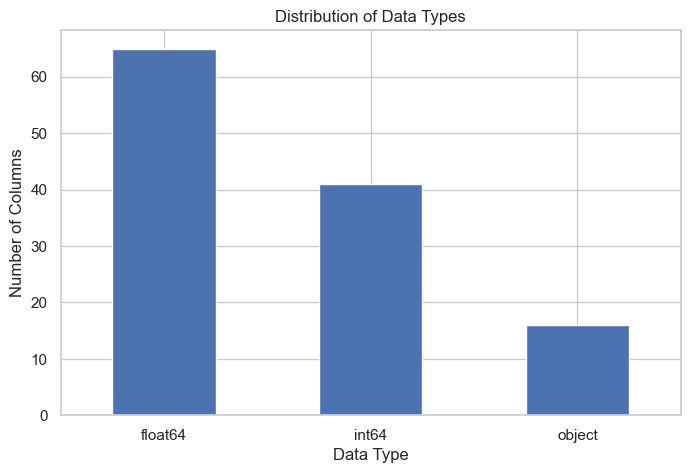

In [27]:

# Count data types

dtype_summary = application_train.dtypes.value_counts()

print(dtype_summary)

# Visualize data types

plt.figure(figsize=(8, 5))

dtype_summary.plot(kind='bar')

plt.title("Distribution of Data Types")
plt.xlabel("Data Type")
plt.ylabel("Number of Columns")
plt.xticks(rotation=0)

plt.show()



###  Statistical Summary

Descriptive statistical analysis is performed to
understand the distribution of numerical variables.

Measures such as mean, median, standard deviation,
minimum and maximum values help identify unusual
values and understand the characteristics of
customer financial information.


In [28]:

# Numerical statistical summary

display(
    application_train.describe().T
)


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0



### Target Variable Distribution

The TARGET variable represents the repayment status
of loan applicants.

- 0 represents non-defaulters.
- 1 represents defaulters.

The distribution of the target variable is analyzed
to determine whether the dataset contains class
imbalance.

Class imbalance can affect model learning and
evaluation, particularly when predicting loan defaults.


Target Counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target Percentages:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


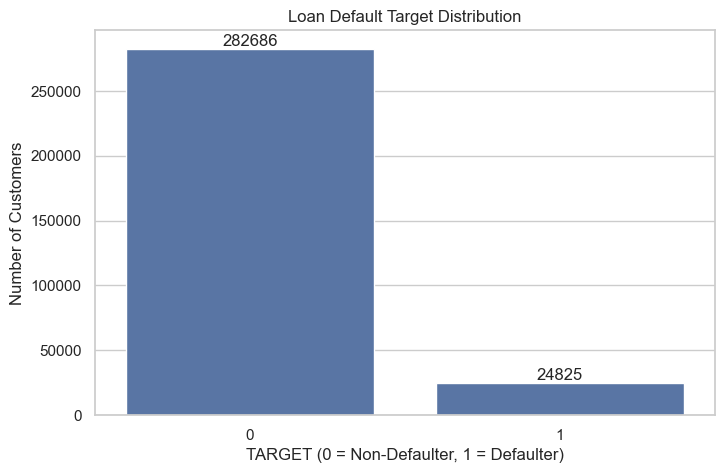

In [29]:

# Calculate target counts

target_counts = application_train['TARGET'].value_counts()

print("Target Counts:")
print(target_counts)

# Calculate percentages

target_percentages = (
    application_train['TARGET']
    .value_counts(normalize=True) * 100
)

print("\nTarget Percentages:")
print(target_percentages.round(2))

# Plot target distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=application_train,
    x='TARGET'
)

plt.title("Loan Default Target Distribution")
plt.xlabel("TARGET (0 = Non-Defaulter, 1 = Defaulter)")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()


In [30]:
non_defaulters = target_counts.get(0, 0)
defaulters = target_counts.get(1, 0)

print("Non-Defaulters:", non_defaulters)
print("Defaulters:", defaulters)
print("Imbalance Ratio:", round(non_defaulters / defaulters, 2))

Non-Defaulters: 282686
Defaulters: 24825
Imbalance Ratio: 11.39


##  Missing Value Analysis

Missing value analysis is performed to identify incomplete data in the application dataset. Understanding missing values is important because they can affect data quality and machine learning model performance.

The analysis includes:
- Total missing values in each column.
- Missing value percentage.
- Identification of columns with high missing percentages.
- Visualization of missing value patterns.

In [31]:
# Calculate missing values
missing_count = application_train.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    application_train.isnull().mean() * 100
)

# Create missing value summary
missing_summary = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percentage': missing_percentage
})

# Keep only columns containing missing values
missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
]

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("Total columns containing missing values:",
      missing_summary.shape[0])

display(missing_summary)

Total columns containing missing values: 67


,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953


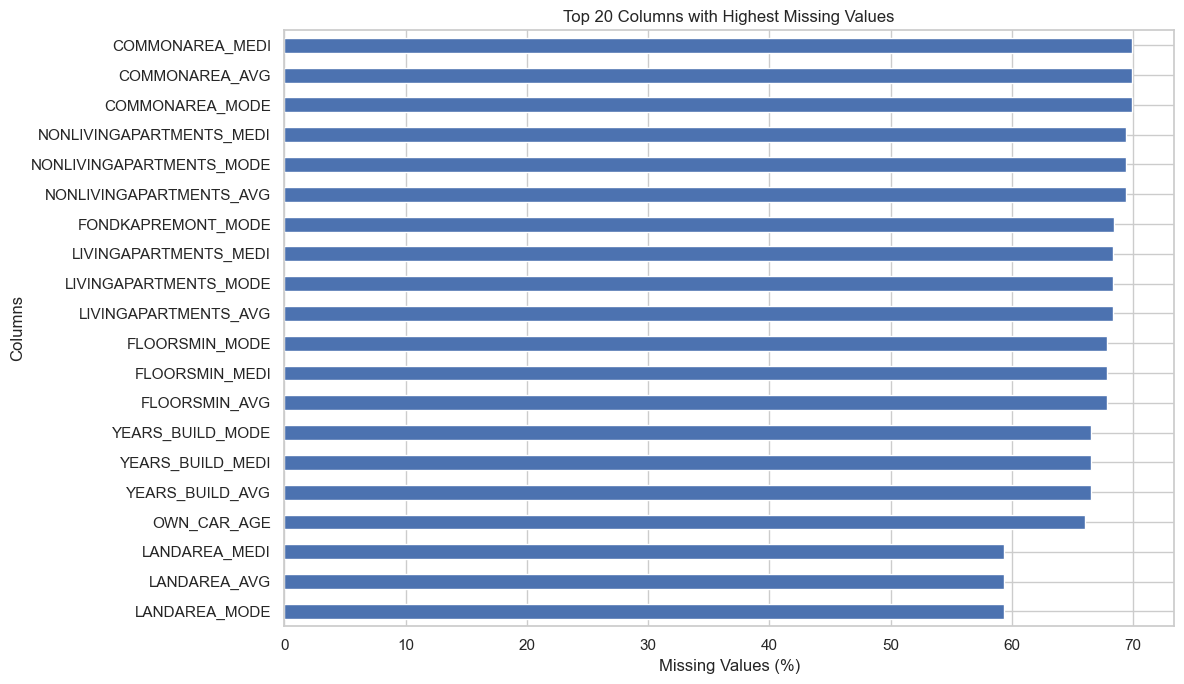

In [32]:
plt.figure(figsize=(12, 7))

missing_summary.head(20)['Missing_Percentage'].sort_values().plot(
    kind='barh'
)

plt.title("Top 20 Columns with Highest Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

### Missing Value Analysis – Key Findings

The missing value analysis identified 67 columns containing missing values in the application dataset.

The highest missing value percentage was observed in property-related features such as COMMONAREA_MEDI, COMMONAREA_AVG, and COMMONAREA_MODE, each having approximately 69.87% missing values.

Other important features, including OCCUPATION_TYPE and EXT_SOURCE_1, also contain a considerable number of missing values.

The analysis indicates that missing data is an important preprocessing challenge. However, removing all columns with missing values could result in the loss of useful predictive information.

Therefore, missing value treatment will be performed carefully during the data preprocessing stage. Numerical and categorical features will be handled using suitable imputation techniques, and the possibility of retaining missing-value indicators will also be considered.

In [33]:
# Check duplicate records
duplicate_count = application_train.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

# Check duplicate customer IDs
duplicate_ids = application_train['SK_ID_CURR'].duplicated().sum()

print("Duplicate Customer IDs:", duplicate_ids)

Total Duplicate Rows: 0
Duplicate Customer IDs: 0


### Duplicate Records Analysis

Duplicate records are checked to identify repeated observations in the dataset.

The customer ID column (SK_ID_CURR) is also examined to verify whether each applicant has a unique identifier.

Duplicate records, if present, will be investigated before further data preprocessing.

In [34]:
# Overall data quality summary

print("DATA QUALITY SUMMARY")
print("-" * 40)

print("Total Records:", application_train.shape[0])
print("Total Features:", application_train.shape[1])

print("Missing Value Columns:", missing_summary.shape[0])

print("Total Missing Values:", application_train.isnull().sum().sum())

print("Duplicate Rows:", application_train.duplicated().sum())

print("Duplicate Customer IDs:",
      application_train['SK_ID_CURR'].duplicated().sum())

print("Unique Customer IDs:",
      application_train['SK_ID_CURR'].nunique())

DATA QUALITY SUMMARY
----------------------------------------
Total Records: 307511
Total Features: 122
Missing Value Columns: 67
Total Missing Values: 9152465
Duplicate Rows: 0
Duplicate Customer IDs: 0
Unique Customer IDs: 307511


##  Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics, distributions, and relationships among the variables in the dataset.

This section focuses on:
- Numerical feature distributions.
- Categorical feature distributions.
- Relationships between applicant characteristics and loan default.
- Identification of unusual values and patterns.

In [35]:
# Select important numerical features

numerical_features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

# Display descriptive statistics
display(application_train[numerical_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,2.565000e+04,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,4.500000e+04,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1.615500e+03,16524.000000,24903.000000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,4.050000e+04,238500.000000,450000.000000,679500.000000,4.050000e+06
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-2.522900e+04,-19682.000000,-15750.000000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-1.791200e+04,-2760.000000,-1213.000000,-289.000000,3.652430e+05
EXT_SOURCE_1,134133.0,0.502130,0.211062,1.456813e-02,0.334007,0.505998,0.675053,9.626928e-01
EXT_SOURCE_2,306851.0,0.514393,0.191060,8.173617e-08,0.392457,0.565961,0.663617,8.549997e-01
EXT_SOURCE_3,246546.0,0.510853,0.194844,5.272652e-04,0.370650,0.535276,0.669057,8.960095e-01


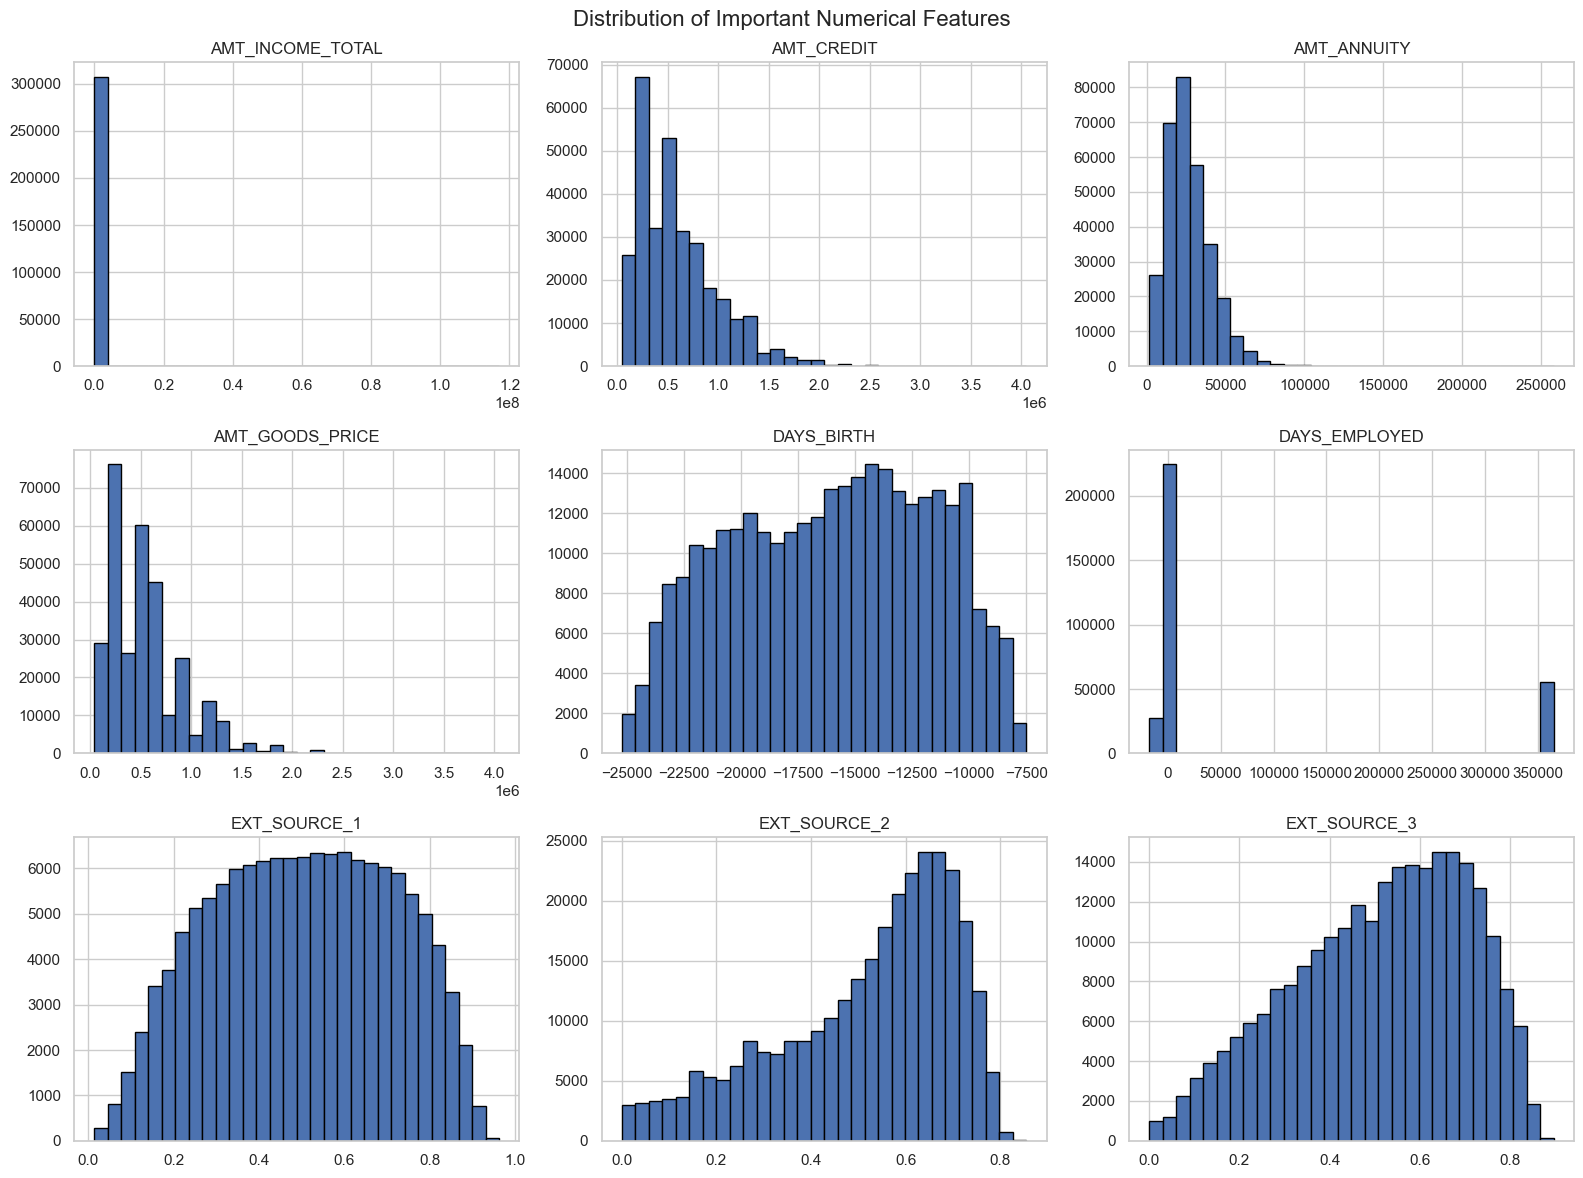

In [36]:
# Plot numerical feature distributions

application_train[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Important Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

Records with DAYS_EMPLOYED = 365243: 55374

Employment Days Statistics:


count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

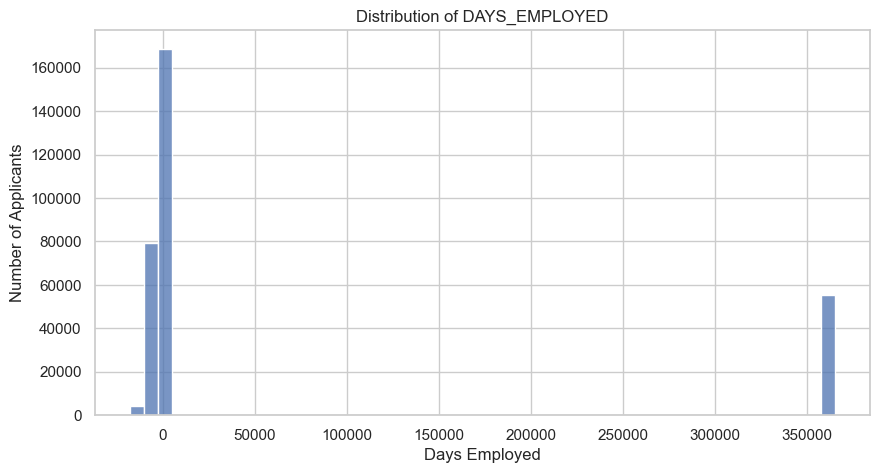

In [37]:
# Investigate unusual DAYS_EMPLOYED values

anomalous_employment = (
    application_train['DAYS_EMPLOYED'] == 365243
).sum()

print("Records with DAYS_EMPLOYED = 365243:",
      anomalous_employment)

print("\nEmployment Days Statistics:")
display(application_train['DAYS_EMPLOYED'].describe())

# Visualize employment days
plt.figure(figsize=(10, 5))

sns.histplot(
    application_train['DAYS_EMPLOYED'],
    bins=50
)

plt.title("Distribution of DAYS_EMPLOYED")
plt.xlabel("Days Employed")
plt.ylabel("Number of Applicants")

plt.show()

### DAYS_EMPLOYED – Anomaly Detection Findings

The analysis of DAYS_EMPLOYED identified an unusual value of 365243 in 55,374 records, representing approximately 18.01% of the applicants.

The histogram shows that this value is significantly different from the normal employment duration values.

This value is treated as an anomalous placeholder rather than a genuine employment duration. Removing these records could result in the loss of valuable customer information.

Therefore, the anomalous value will be handled during data preprocessing. A separate indicator feature may also be created to preserve information about applicants with this special value.

##  Categorical Feature Analysis

Categorical feature analysis is performed to understand the distribution of applicants across different demographic, financial, and employment categories.

The analysis examines important categorical variables such as contract type, gender, income type, education, family status, occupation, and housing type.

In [38]:
# Select important categorical features

categorical_features = [
    'NAME_CONTRACT_TYPE',
    'CODE_GENDER',
    'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS',
    'OCCUPATION_TYPE',
    'NAME_HOUSING_TYPE'
]

# Display category counts

for feature in categorical_features:

    print("\n" + "=" * 60)
    print("Feature:", feature)
    print("=" * 60)

    display(
        application_train[feature]
        .value_counts(dropna=False)
        .to_frame(name='Count')
    )


Feature: NAME_CONTRACT_TYPE


,Count
NAME_CONTRACT_TYPE,
Cash loans,278232
Revolving loans,29279



Feature: CODE_GENDER


,Count
CODE_GENDER,
F,202448
M,105059
XNA,4



Feature: NAME_INCOME_TYPE


,Count
NAME_INCOME_TYPE,
Working,158774
Commercial associate,71617
Pensioner,55362
State servant,21703
Unemployed,22
Student,18
Businessman,10
Maternity leave,5


... (4 outputs left out)


Feature: OCCUPATION_TYPE


,Count
OCCUPATION_TYPE,
NaN,96391
Laborers,55186
Sales staff,32102
Core staff,27570
Managers,21371
Drivers,18603
High skill tech staff,11380
Accountants,9813
Medicine staff,8537



Feature: NAME_HOUSING_TYPE


,Count
NAME_HOUSING_TYPE,
House / apartment,272868
With parents,14840
Municipal apartment,11183
Rented apartment,4881
Office apartment,2617
Co-op apartment,1122


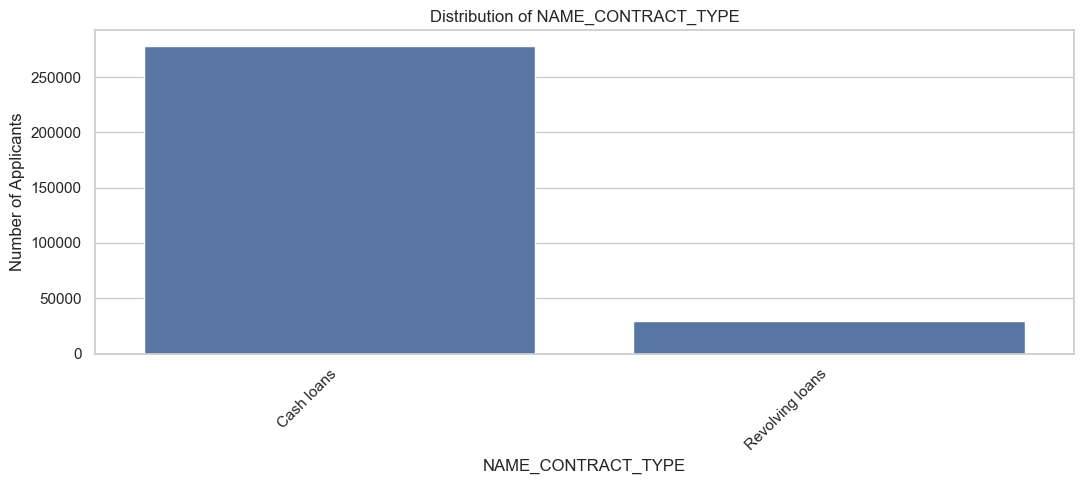

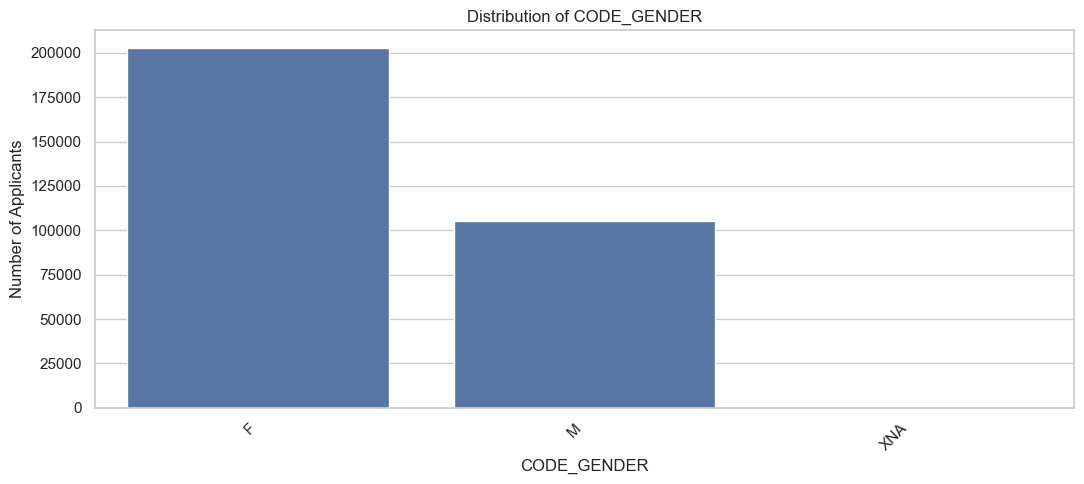

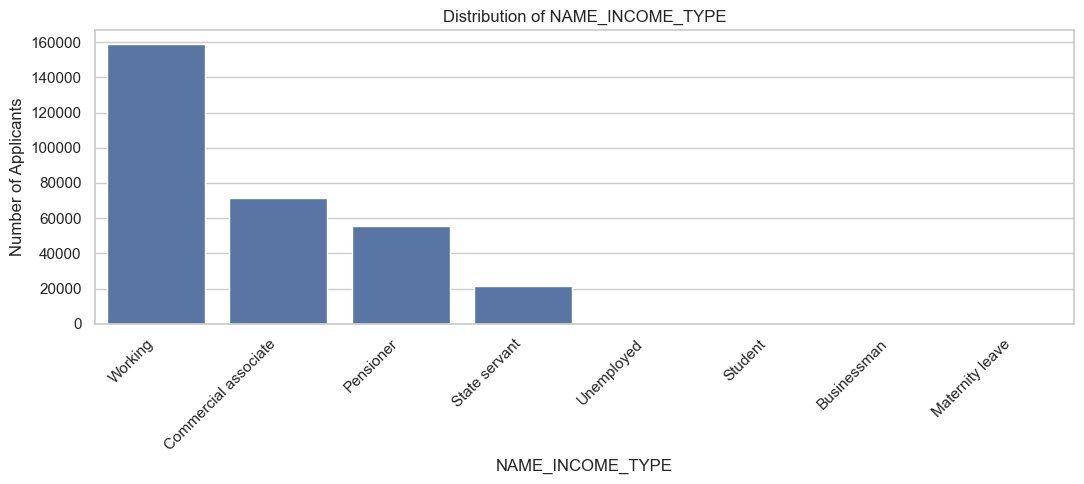

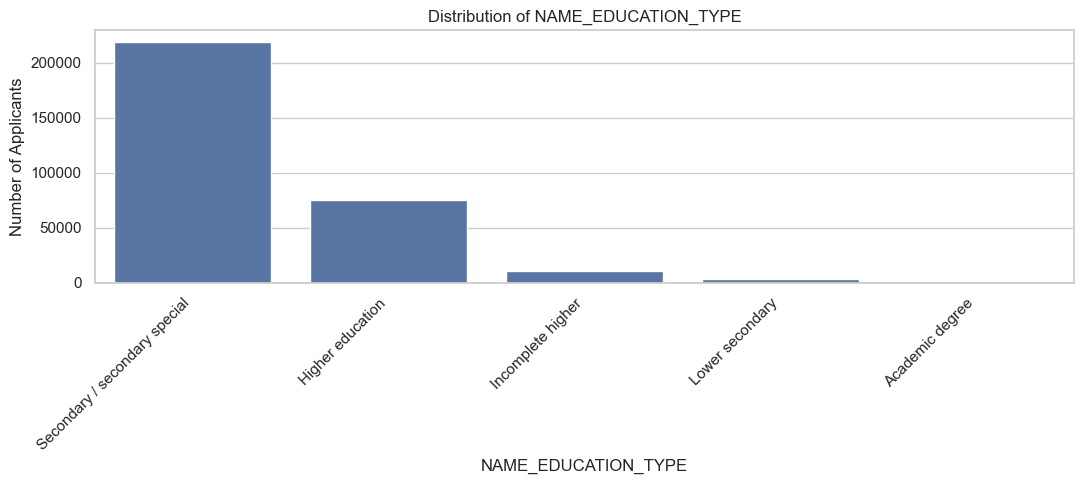

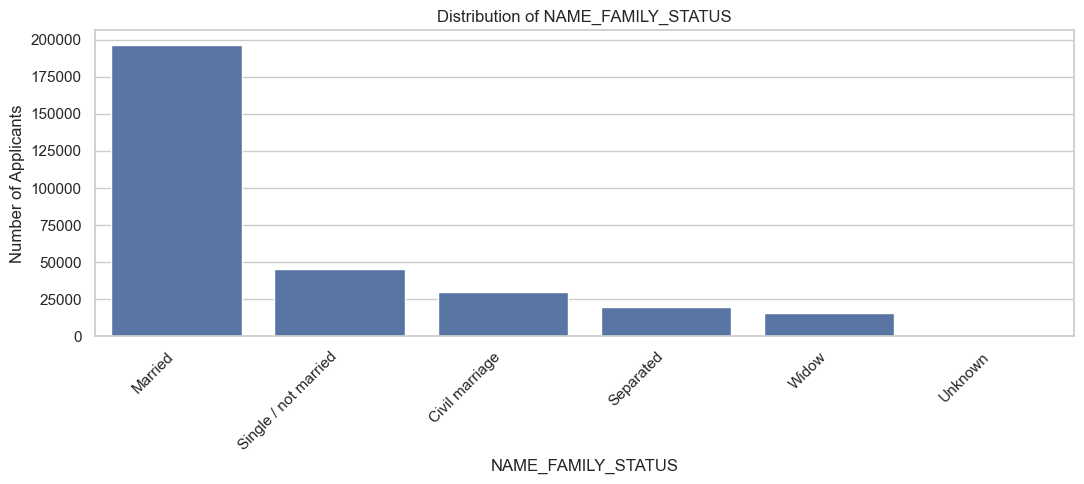

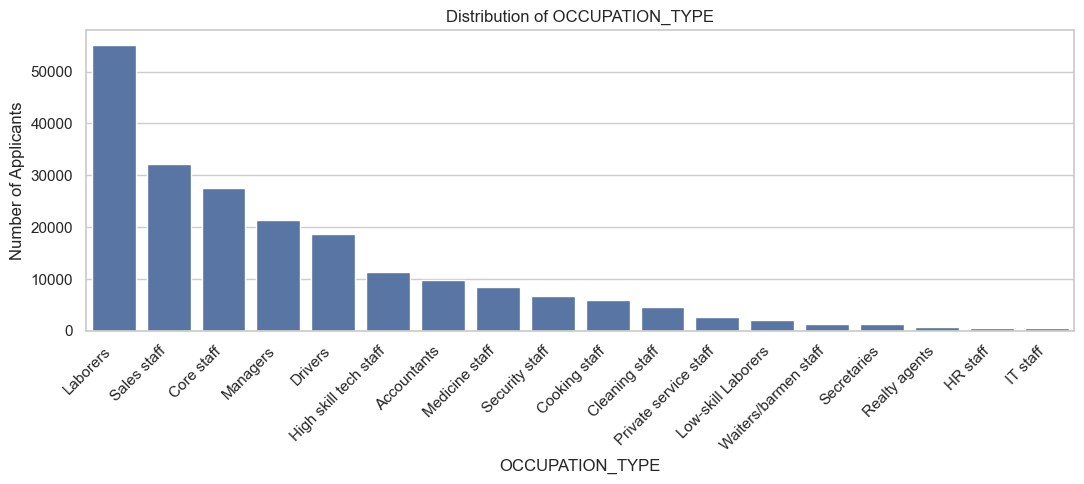

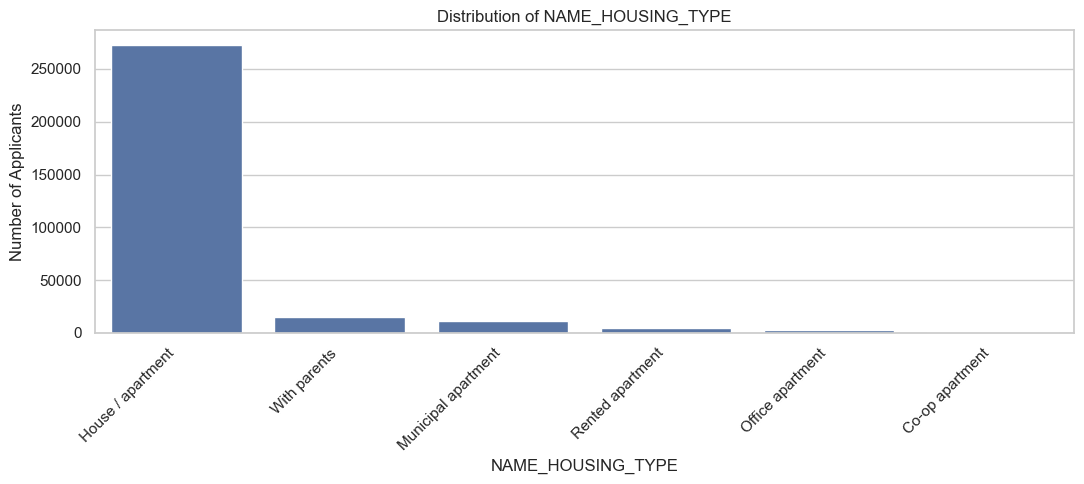

In [39]:
# Visualize categorical feature distributions

for feature in categorical_features:

    plt.figure(figsize=(11, 5))

    order = application_train[feature].value_counts().index

    sns.countplot(
        data=application_train,
        x=feature,
        order=order
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Applicants")
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

## Default Rate Analysis by Categorical Features

Default rate analysis is performed to understand the proportion of loan defaulters across different applicant categories.

The default rate is calculated using the TARGET variable, where:

- 0 represents non-defaulters.
- 1 represents defaulters.

This analysis helps identify category-level differences in historical loan default patterns.

In [40]:
# Calculate default rates for categorical features

for feature in categorical_features:

    default_analysis = (
        application_train
        .groupby(feature, dropna=False)['TARGET']
        .agg(['count', 'mean'])
        .reset_index()
    )

    default_analysis['Default_Rate_Percentage'] = (
        default_analysis['mean'] * 100
    )

    default_analysis = default_analysis.sort_values(
        by='Default_Rate_Percentage',
        ascending=False
    )

    print("\n" + "=" * 70)
    print("Default Rate Analysis:", feature)
    print("=" * 70)

    display(
        default_analysis[
            [feature, 'count', 'Default_Rate_Percentage']
        ].round(2)
    )


Default Rate Analysis: NAME_CONTRACT_TYPE


,NAME_CONTRACT_TYPE,count,Default_Rate_Percentage
0,Cash loans,278232,8.35
1,Revolving loans,29279,5.48



Default Rate Analysis: CODE_GENDER


,CODE_GENDER,count,Default_Rate_Percentage
1,M,105059,10.14
0,F,202448,7.00
2,XNA,4,0.00



Default Rate Analysis: NAME_INCOME_TYPE


,NAME_INCOME_TYPE,count,Default_Rate_Percentage
2,Maternity leave,5,40.00
6,Unemployed,22,36.36
7,Working,158774,9.59
1,Commercial associate,71617,7.48
4,State servant,21703,5.75
3,Pensioner,55362,5.39
0,Businessman,10,0.00
5,Student,18,0.00


... (4 outputs left out)


Default Rate Analysis: OCCUPATION_TYPE


,OCCUPATION_TYPE,count,Default_Rate_Percentage
9,Low-skill Laborers,2093,17.15
4,Drivers,18603,11.33
17,Waiters/barmen staff,1348,11.28
16,Security staff,6721,10.74
8,Laborers,55186,10.58
2,Cooking staff,5946,10.44
14,Sales staff,32102,9.63
1,Cleaning staff,4653,9.61
13,Realty agents,751,7.86
15,Secretaries,1305,7.05



Default Rate Analysis: NAME_HOUSING_TYPE


,NAME_HOUSING_TYPE,count,Default_Rate_Percentage
4,Rented apartment,4881,12.31
5,With parents,14840,11.70
2,Municipal apartment,11183,8.54
0,Co-op apartment,1122,7.93
1,House / apartment,272868,7.80
3,Office apartment,2617,6.57


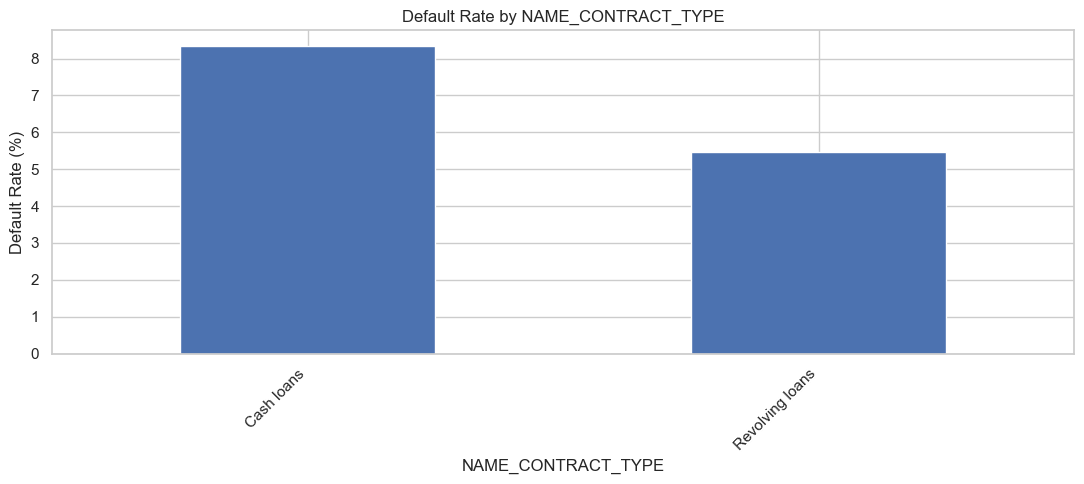

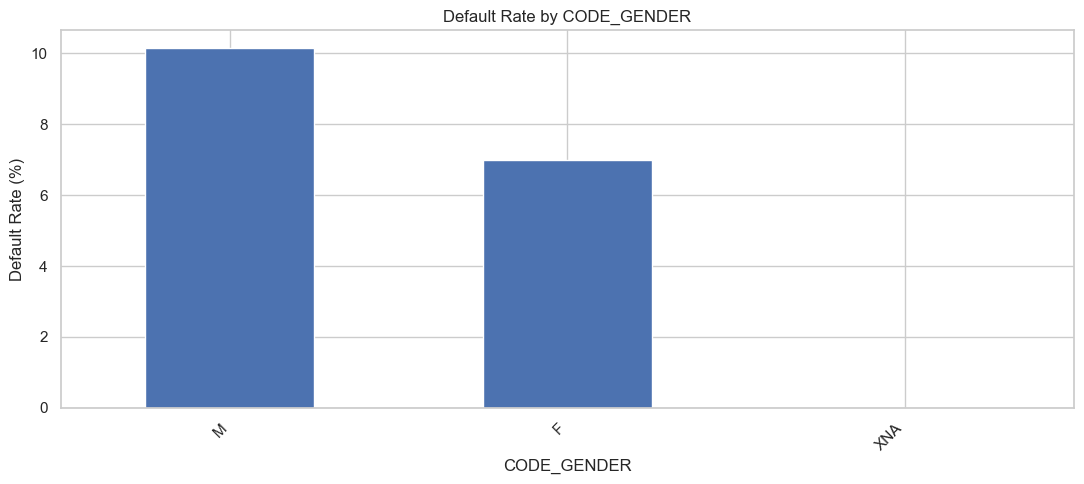

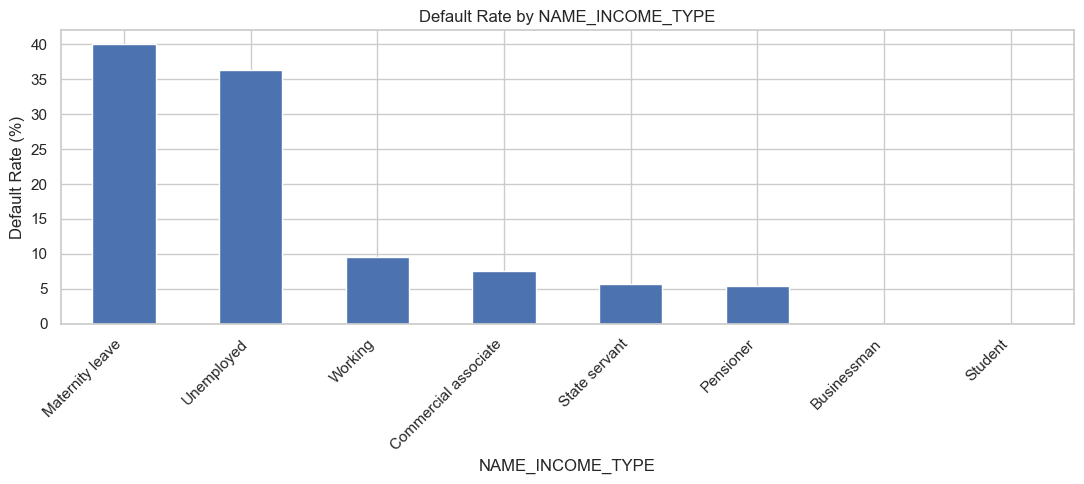

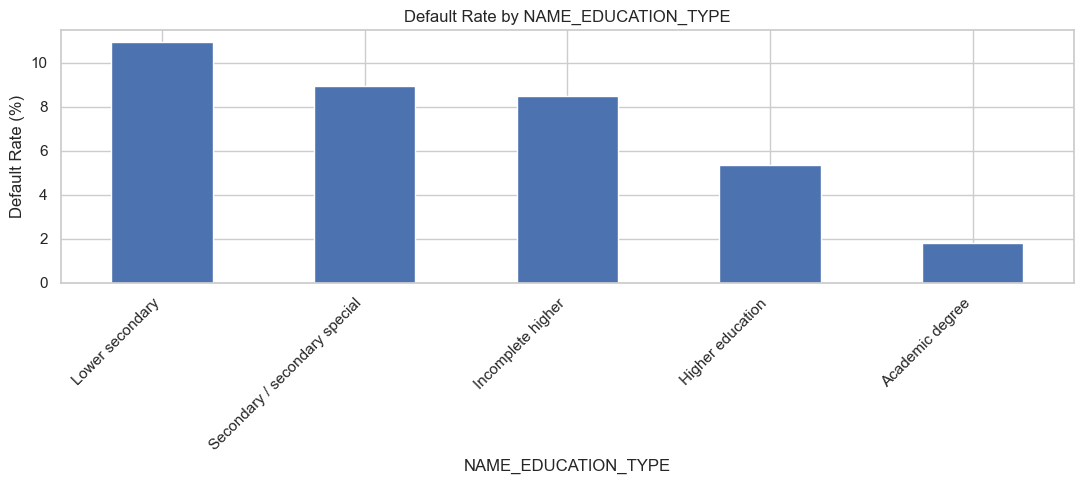

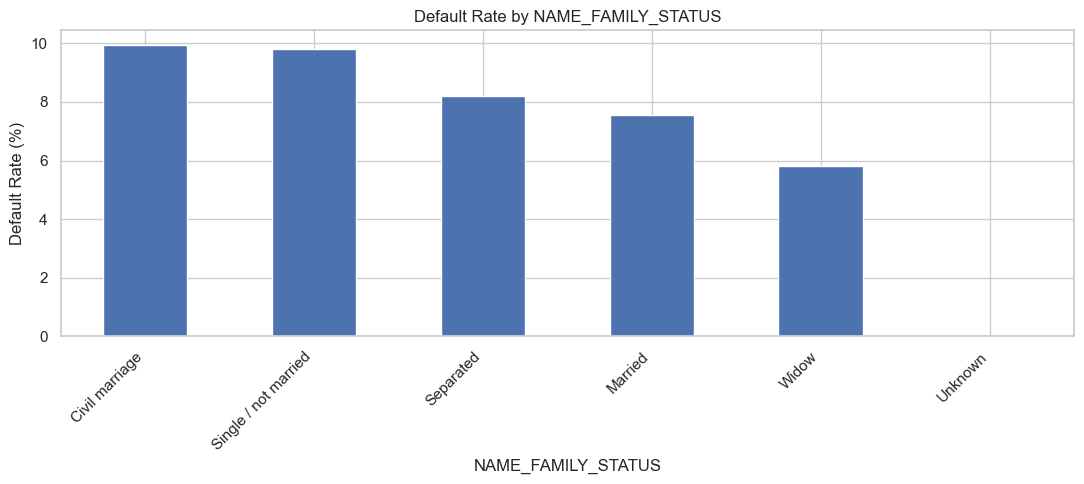

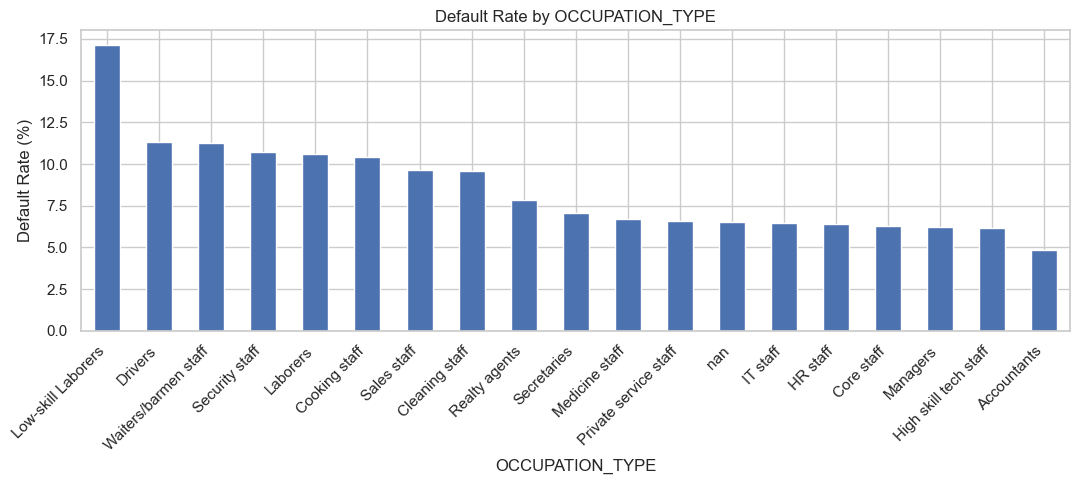

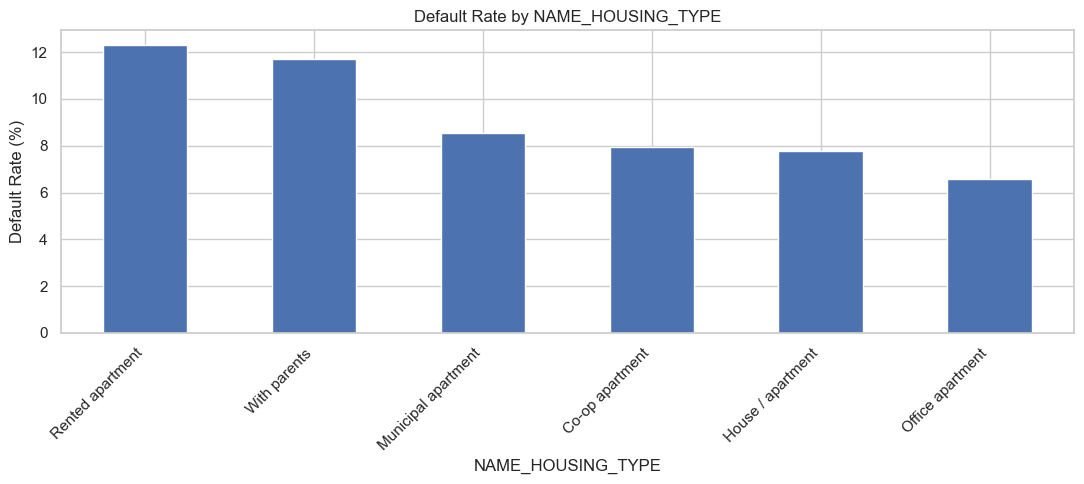

In [41]:
# Visualize default rates by categorical features

for feature in categorical_features:

    default_rates = (
        application_train
        .groupby(feature, dropna=False)['TARGET']
        .mean() * 100
    )

    default_rates = default_rates.sort_values(
        ascending=False
    )

    plt.figure(figsize=(11, 5))

    default_rates.plot(kind='bar')

    plt.title(f"Default Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Default Rate (%)")
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

### Default Rate Analysis by Categorical Features – Key Findings

The categorical default rate analysis reveals differences in historical loan default rates across applicant groups.

Cash loan applicants have an observed default rate of 8.35%, compared with 5.48% for revolving loan applicants. Among the occupation categories, Low-skill Laborers have the highest observed default rate at 17.15%. Applicants living in rented apartments have an observed default rate of 12.31%.

Education-level analysis shows a default rate of 10.93% for applicants with lower secondary education and 5.36% for applicants with higher education.

These findings help identify patterns and relationships between categorical variables and loan repayment outcomes.

However, categories with very small sample sizes may produce unstable default rate estimates. Therefore, these results should be interpreted carefully and should not be considered proof of individual default risk.

##  Numerical Feature Analysis by Target

This analysis compares numerical features between defaulters and non-defaulters to identify differences in financial and applicant characteristics.

The comparison uses descriptive statistics and boxplots to understand how numerical variables relate to loan repayment outcomes.

In [42]:
# Compare numerical features by TARGET

for feature in numerical_features:

    print("\n" + "=" * 60)
    print("Feature:", feature)
    print("=" * 60)

    display(
        application_train
        .groupby('TARGET')[feature]
        .agg(['count', 'mean', 'median', 'std'])
        .round(2)
    )


Feature: AMT_INCOME_TOTAL


,count,mean,median,std
TARGET,,,,
0,282686,169077.72,148500.0,110476.27
1,24825,165611.76,135000.0,746676.96



Feature: AMT_CREDIT


,count,mean,median,std
TARGET,,,,
0,282686,602648.28,517788.0,406845.91
1,24825,557778.53,497520.0,346433.24



Feature: AMT_ANNUITY


,count,mean,median,std
TARGET,,,,
0,282674,27163.62,24876.0,14658.31
1,24825,26481.74,25263.0,12450.68


... (8 outputs left out)


Feature: EXT_SOURCE_2


,count,mean,median,std
TARGET,,,,
0,282078,0.52,0.57,0.19
1,24773,0.41,0.44,0.21



Feature: EXT_SOURCE_3


,count,mean,median,std
TARGET,,,,
0,227398,0.52,0.55,0.19
1,19148,0.39,0.38,0.21


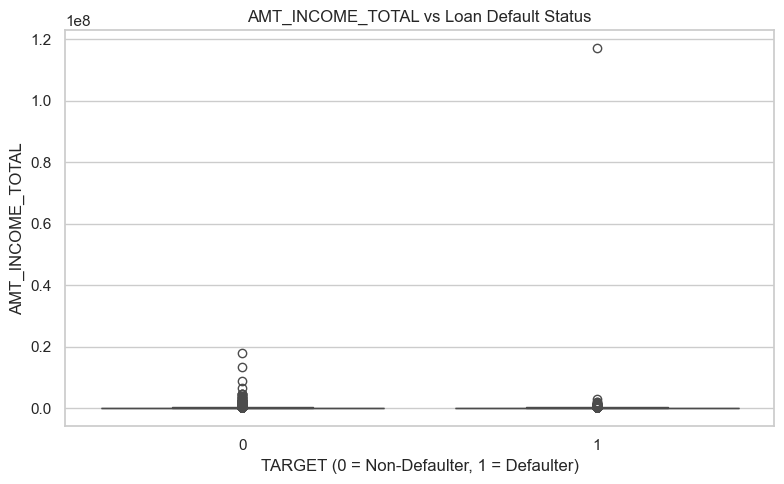

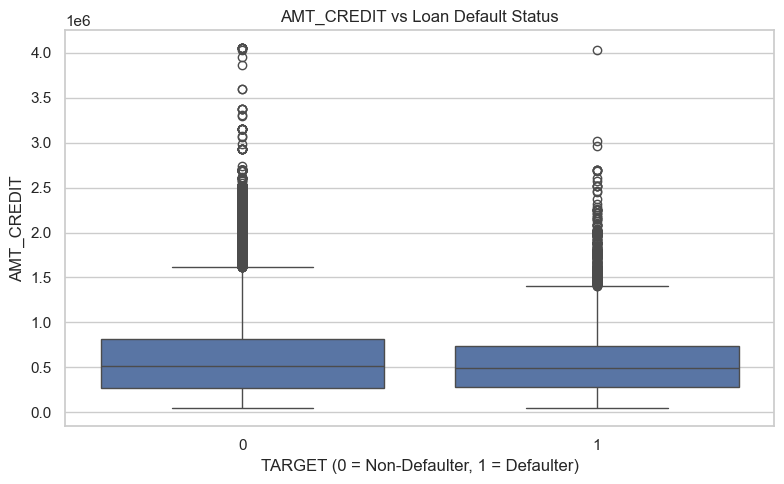

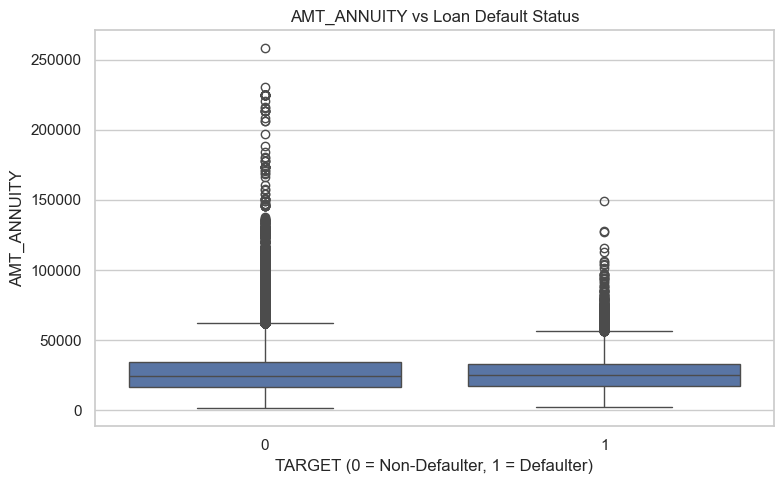

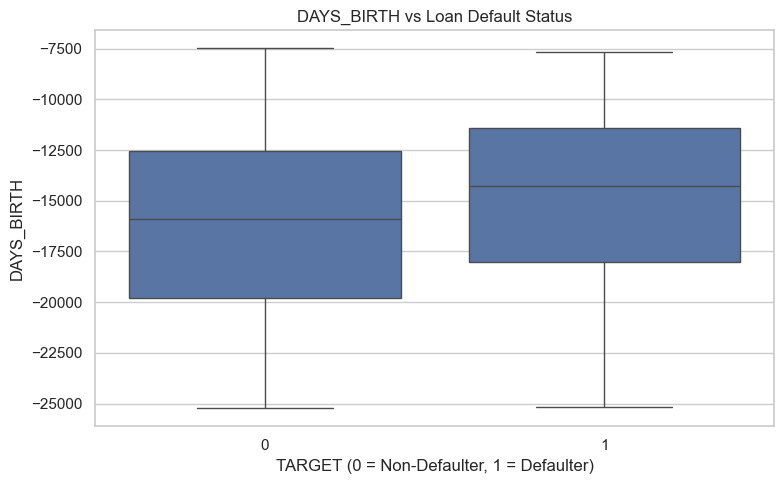

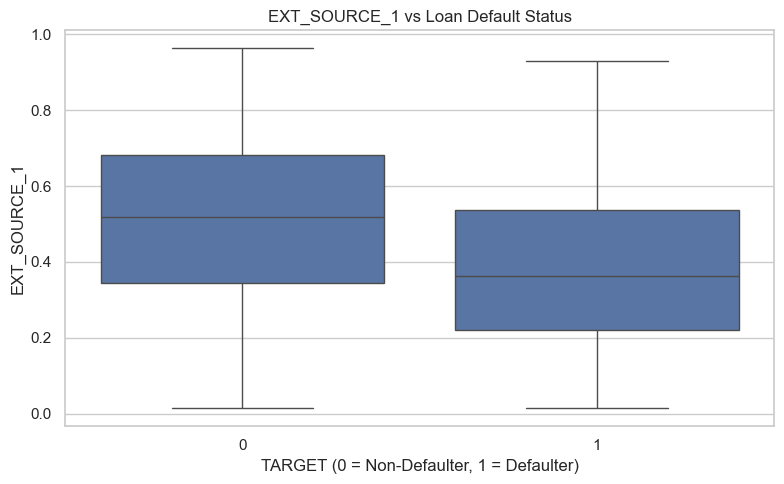

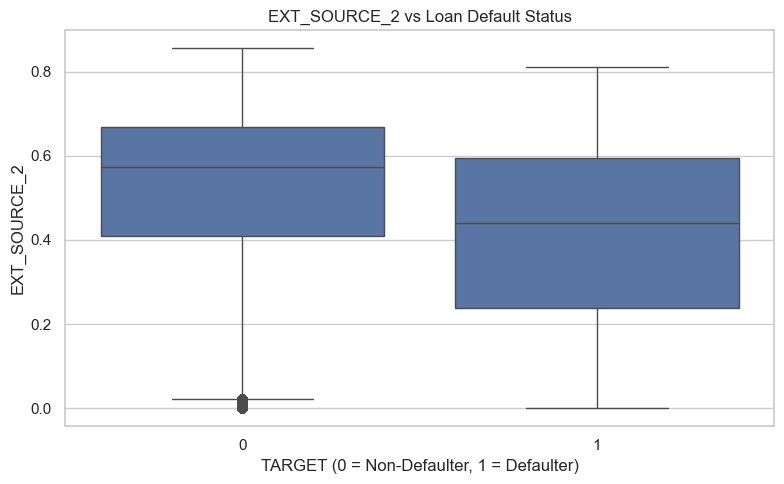

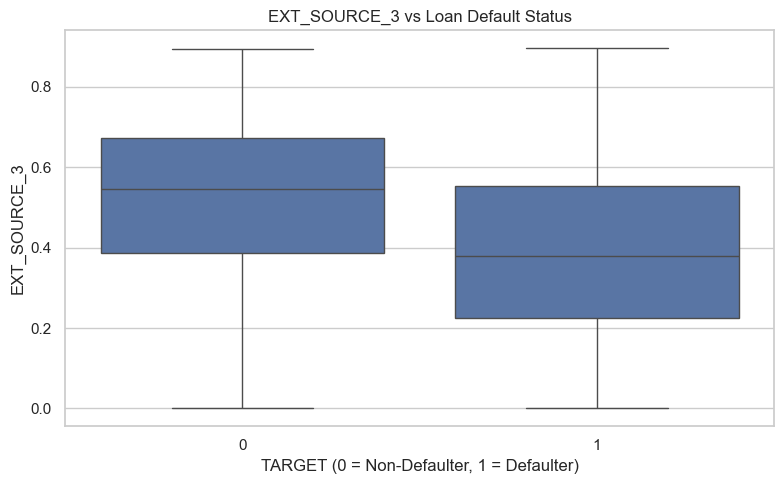

In [43]:
# Compare numerical distributions between defaulters
# and non-defaulters

selected_features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'DAYS_BIRTH',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

for feature in selected_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=application_train,
        x='TARGET',
        y=feature
    )

    plt.title(f"{feature} vs Loan Default Status")
    plt.xlabel("TARGET (0 = Non-Defaulter, 1 = Defaulter)")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

## Correlation Analysis

Correlation analysis is performed to understand the relationships between numerical features and the target variable.

A correlation matrix and heatmap are used to identify strongly related variables and possible multicollinearity among numerical features.

Correlation does not imply causation.

In [44]:
# Select numerical features for correlation analysis

correlation_features = [
    'TARGET',
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

# Calculate Pearson correlation
correlation_matrix = application_train[
    correlation_features
].corr()

# Display correlation with TARGET
target_correlation = (
    correlation_matrix['TARGET']
    .drop('TARGET')
    .sort_values()
)

print("Correlation of Features with TARGET:")
display(target_correlation.to_frame(name='Correlation'))

Correlation of Features with TARGET:


,Correlation
EXT_SOURCE_3,-0.178919
EXT_SOURCE_2,-0.160472
EXT_SOURCE_1,-0.155317
DAYS_EMPLOYED,-0.044932
AMT_GOODS_PRICE,-0.039645
AMT_CREDIT,-0.030369
AMT_ANNUITY,-0.012817
AMT_INCOME_TOTAL,-0.003982
DAYS_BIRTH,0.078239


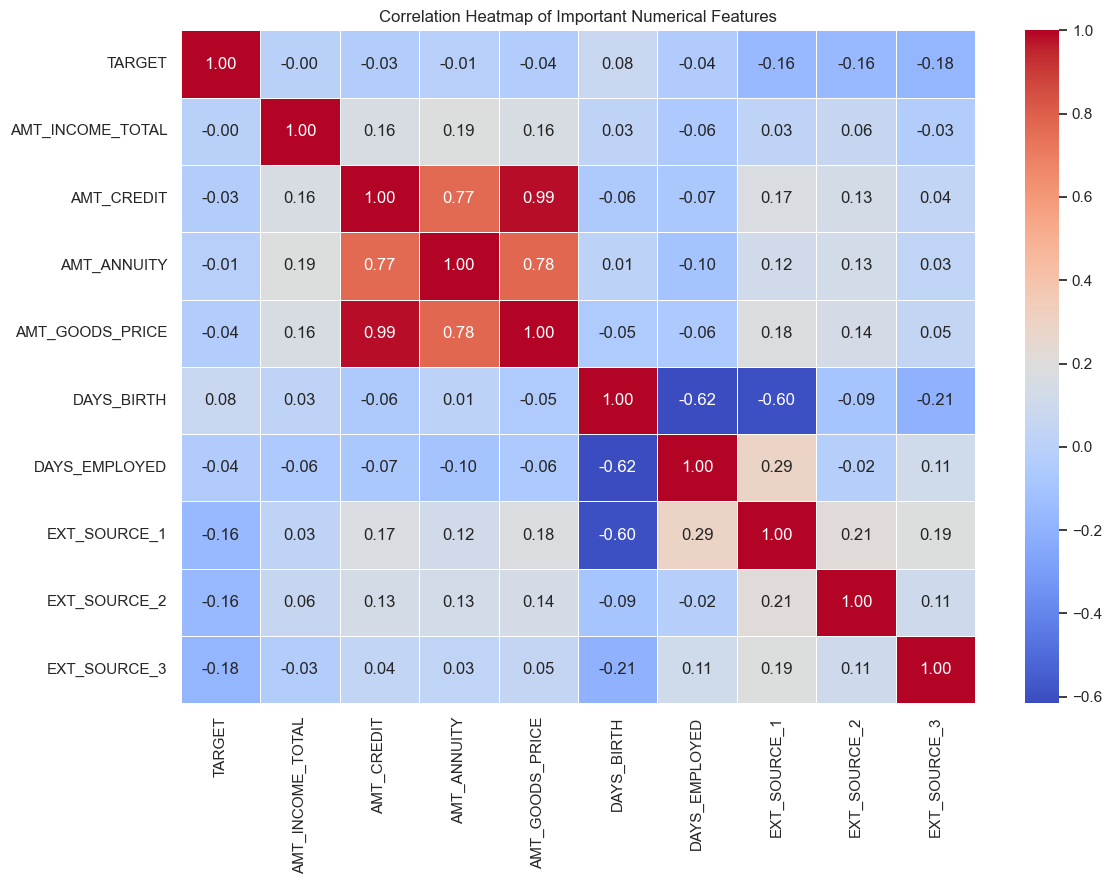

In [45]:
# Plot correlation heatmap

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Important Numerical Features")
plt.tight_layout()
plt.show()

## Supporting Dataset Exploration

The Home Loan Default Prediction project contains six additional datasets that provide historical information about applicants' previous credit accounts, loan applications, credit card usage, POS cash loans, and installment payments.

These datasets will be explored to identify useful historical financial features.

The supporting datasets will later be aggregated at the customer level using appropriate identifiers and integrated with the main application dataset.

In [46]:
# Load supporting datasets

bureau = pd.read_csv('bureau.csv')
bureau_balance = pd.read_csv('bureau_balance.csv')

previous_application = pd.read_csv('previous_application.csv')

pos_cash = pd.read_csv('POS_CASH_balance.csv')

credit_card = pd.read_csv('credit_card_balance.csv')

installments = pd.read_csv('installments_payments.csv')

print("All supporting datasets loaded successfully!")

All supporting datasets loaded successfully!


In [47]:
# Display dataset dimensions

datasets = {
    'bureau': bureau,
    'bureau_balance': bureau_balance,
    'previous_application': previous_application,
    'POS_CASH_balance': pos_cash,
    'credit_card_balance': credit_card,
    'installments_payments': installments
}

for name, df in datasets.items():

    print(f"{name}: {df.shape[0]} rows and {df.shape[1]} columns")

bureau: 1716428 rows and 17 columns
bureau_balance: 27299925 rows and 3 columns
previous_application: 1670214 rows and 37 columns
POS_CASH_balance: 10001358 rows and 8 columns
credit_card_balance: 3840312 rows and 23 columns
installments_payments: 13605401 rows and 8 columns


###  Supporting Dataset Structure Analysis

The structure of each supporting dataset is examined to understand its columns, data types, and available information.

This analysis helps identify customer identifiers, previous loan identifiers, historical financial variables, and other useful attributes required for feature engineering.

In [48]:
# Inspect the structure of all supporting datasets

for name, df in datasets.items():

    print("\n" + "=" * 80)
    print("DATASET:", name.upper())
    print("=" * 80)

    print("Shape:", df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes.value_counts())

    print("\nFirst 3 Records:")
    display(df.head(3))


DATASET: BUREAU
Shape: (1716428, 17)

Column Names:
['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']

Data Types:
float64    8
int64      6
object     3
Name: count, dtype: int64

First 3 Records:


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN



DATASET: BUREAU_BALANCE
Shape: (27299925, 3)

Column Names:
['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']

Data Types:
int64     2
object    1
Name: count, dtype: int64

First 3 Records:


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C



DATASET: PREVIOUS_APPLICATION
Shape: (1670214, 37)

Column Names:
['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL']

Data Types:
object     16
float64    15
int64       6
Name: count, dtype: int64

First 3 Records:


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,Y,1,0.0,0.182832,0.867336,XAP,Approved,-73,Cash through the bank,XAP,NaN,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0


... (2 outputs left out)


DATASET: CREDIT_CARD_BALANCE
Shape: (3840312, 23)

Column Names:
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT', 'AMT_DRAWINGS_OTHER_CURRENT', 'AMT_DRAWINGS_POS_CURRENT', 'AMT_INST_MIN_REGULARITY', 'AMT_PAYMENT_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'AMT_RECEIVABLE_PRINCIPAL', 'AMT_RECIVABLE', 'AMT_TOTAL_RECEIVABLE', 'CNT_DRAWINGS_ATM_CURRENT', 'CNT_DRAWINGS_CURRENT', 'CNT_DRAWINGS_OTHER_CURRENT', 'CNT_DRAWINGS_POS_CURRENT', 'CNT_INSTALMENT_MATURE_CUM', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']

Data Types:
float64    15
int64       7
object      1
Name: count, dtype: int64

First 3 Records:


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_CURRENT,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,1800.0,1800.0,0.000,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,2250.0,2250.0,60175.080,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,2250.0,2250.0,26926.425,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0



DATASET: INSTALLMENTS_PAYMENTS
Shape: (13605401, 8)

Column Names:
['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT']

Data Types:
float64    5
int64      3
Name: count, dtype: int64

First 3 Records:


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000


In [49]:
# Missing value analysis for supporting datasets

for name, df in datasets.items():

    missing_count = df.isnull().sum()

    missing_percentage = (
        df.isnull().mean() * 100
    )

    missing_report = pd.DataFrame({
        'Missing_Count': missing_count,
        'Missing_Percentage': missing_percentage
    })

    missing_report = missing_report[
        missing_report['Missing_Count'] > 0
    ].sort_values(
        by='Missing_Percentage',
        ascending=False
    )

    print("\n" + "=" * 80)
    print("MISSING VALUES:", name.upper())
    print("=" * 80)

    if missing_report.empty:
        print("No missing values found.")
    else:
        display(missing_report)


MISSING VALUES: BUREAU


,Missing_Count,Missing_Percentage
AMT_ANNUITY,1226791,71.473490
AMT_CREDIT_MAX_OVERDUE,1124488,65.513264
DAYS_ENDDATE_FACT,633653,36.916958
AMT_CREDIT_SUM_LIMIT,591780,34.477415
AMT_CREDIT_SUM_DEBT,257669,15.011932
DAYS_CREDIT_ENDDATE,105553,6.149573
AMT_CREDIT_SUM,13,0.000757



MISSING VALUES: BUREAU_BALANCE
No missing values found.

MISSING VALUES: PREVIOUS_APPLICATION


,Missing_Count,Missing_Percentage
RATE_INTEREST_PRIMARY,1664263,99.643698
RATE_INTEREST_PRIVILEGED,1664263,99.643698
AMT_DOWN_PAYMENT,895844,53.636480
RATE_DOWN_PAYMENT,895844,53.636480
NAME_TYPE_SUITE,820405,49.119754
DAYS_FIRST_DRAWING,673065,40.298129
DAYS_FIRST_DUE,673065,40.298129
DAYS_LAST_DUE_1ST_VERSION,673065,40.298129
DAYS_LAST_DUE,673065,40.298129
DAYS_TERMINATION,673065,40.298129



MISSING VALUES: POS_CASH_BALANCE


,Missing_Count,Missing_Percentage
CNT_INSTALMENT_FUTURE,26087,0.260835
CNT_INSTALMENT,26071,0.260675



MISSING VALUES: CREDIT_CARD_BALANCE


,Missing_Count,Missing_Percentage
AMT_PAYMENT_CURRENT,767988,19.998063
AMT_DRAWINGS_ATM_CURRENT,749816,19.524872
AMT_DRAWINGS_OTHER_CURRENT,749816,19.524872
AMT_DRAWINGS_POS_CURRENT,749816,19.524872
CNT_DRAWINGS_ATM_CURRENT,749816,19.524872
CNT_DRAWINGS_OTHER_CURRENT,749816,19.524872
CNT_DRAWINGS_POS_CURRENT,749816,19.524872
AMT_INST_MIN_REGULARITY,305236,7.948208
CNT_INSTALMENT_MATURE_CUM,305236,7.948208



MISSING VALUES: INSTALLMENTS_PAYMENTS


,Missing_Count,Missing_Percentage
DAYS_ENTRY_PAYMENT,2905,0.021352
AMT_PAYMENT,2905,0.021352


###  Customer Identifier and Relationship Analysis

The customer identifier SK_ID_CURR is used to connect historical financial records with the main application dataset.

The previous loan identifier SK_ID_PREV connects historical POS, credit card, installment, and previous application records.

The bureau identifier SK_ID_BUREAU connects bureau records with monthly bureau balance information.

This analysis verifies the relationships between datasets before feature aggregation.

In [50]:
# Analyze unique identifiers in supporting datasets

for name, df in datasets.items():

    print("\n" + "=" * 65)
    print("DATASET:", name.upper())
    print("=" * 65)

    if 'SK_ID_CURR' in df.columns:
        print(
            "Unique Customers:",
            df['SK_ID_CURR'].nunique()
        )

    if 'SK_ID_PREV' in df.columns:
        print(
            "Unique Previous Loans:",
            df['SK_ID_PREV'].nunique()
        )

    if 'SK_ID_BUREAU' in df.columns:
        print(
            "Unique Bureau Credits:",
            df['SK_ID_BUREAU'].nunique()
        )


DATASET: BUREAU
Unique Customers: 305811
Unique Bureau Credits: 1716428

DATASET: BUREAU_BALANCE
Unique Bureau Credits: 817395

DATASET: PREVIOUS_APPLICATION
Unique Customers: 338857
Unique Previous Loans: 1670214

DATASET: POS_CASH_BALANCE
Unique Customers: 337252
Unique Previous Loans: 936325

DATASET: CREDIT_CARD_BALANCE
Unique Customers: 103558
Unique Previous Loans: 104307

DATASET: INSTALLMENTS_PAYMENTS
Unique Customers: 339587
Unique Previous Loans: 997752


In [51]:
# Check customer ID coverage

main_customer_ids = set(application_train['SK_ID_CURR'].unique())

for name, df in datasets.items():

    if 'SK_ID_CURR' in df.columns:

        supporting_customer_ids = set(
            df['SK_ID_CURR'].unique()
        )

        matched_customers = len(
            main_customer_ids.intersection(
                supporting_customer_ids
            )
        )

        print("\nDataset:", name)

        print(
            "Customers matching main dataset:",
            matched_customers
        )

        print(
            "Customers not matching main dataset:",
            len(supporting_customer_ids) - matched_customers
        )


Dataset: bureau
Customers matching main dataset: 263491
Customers not matching main dataset: 42320

Dataset: previous_application
Customers matching main dataset: 291057
Customers not matching main dataset: 47800

Dataset: POS_CASH_balance
Customers matching main dataset: 289444
Customers not matching main dataset: 47808

Dataset: credit_card_balance
Customers matching main dataset: 86905
Customers not matching main dataset: 16653

Dataset: installments_payments
Customers matching main dataset: 291643
Customers not matching main dataset: 47944


##  Feature Engineering

### Bureau Dataset Analysis

The bureau dataset contains information about applicants' previous credits obtained from external credit institutions.

The bureau_balance dataset provides monthly status information for these previous credits.

Both datasets will be connected using SK_ID_BUREAU. The resulting information will be aggregated by SK_ID_CURR to create customer-level historical credit features.

In [52]:
# Inspect bureau dataset columns

print("BUREAU DATASET")
print("Shape:", bureau.shape)
print("\nColumns:")
print(bureau.columns.tolist())

print("\nData Types:")
print(bureau.dtypes)

print("\nSample Records:")
display(bureau.head(5))


# Inspect bureau balance dataset

print("\nBUREAU BALANCE DATASET")
print("Shape:", bureau_balance.shape)
print("\nColumns:")
print(bureau_balance.columns.tolist())

print("\nData Types:")
print(bureau_balance.dtypes)

print("\nSample Records:")
display(bureau_balance.head(5))

BUREAU DATASET
Shape: (1716428, 17)

Columns:
['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']

Data Types:
SK_ID_CURR                  int64
SK_ID_BUREAU                int64
CREDIT_ACTIVE              object
CREDIT_CURRENCY            object
DAYS_CREDIT                 int64
CREDIT_DAY_OVERDUE          int64
DAYS_CREDIT_ENDDATE       float64
DAYS_ENDDATE_FACT         float64
AMT_CREDIT_MAX_OVERDUE    float64
CNT_CREDIT_PROLONG          int64
AMT_CREDIT_SUM            float64
AMT_CREDIT_SUM_DEBT       float64
AMT_CREDIT_SUM_LIMIT      float64
AMT_CREDIT_SUM_OVERDUE    float64
CREDIT_TYPE                object
DAYS_CREDIT_UPDATE          int64
AMT_ANNUITY               float64
dtype: object

Sample Re

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN



BUREAU BALANCE DATASET
Shape: (27299925, 3)

Columns:
['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']

Data Types:
SK_ID_BUREAU       int64
MONTHS_BALANCE     int64
STATUS            object
dtype: object

Sample Records:


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


### Bureau Balance Feature Aggregation

The bureau_balance dataset contains monthly credit status information for previous loans.

The dataset is connected to the bureau dataset through SK_ID_BUREAU.

We create customer-relevant historical features, including:
- Number of monthly records
- Earliest and latest recorded months
- Number of delinquent monthly records
- Delinquency rate
- Number of unique credit statuses

These features summarize historical credit repayment behaviour.

In [53]:
# Create a delinquency indicator
# Status values 1 to 5 represent overdue credit status

bureau_balance['BB_IS_DELINQUENT'] = (
    bureau_balance['STATUS']
    .isin(['1', '2', '3', '4', '5'])
    .astype('int8')
)

# Aggregate monthly records by bureau credit ID

bureau_balance_features = (
    bureau_balance
    .groupby('SK_ID_BUREAU')
    .agg(
        BB_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),
        BB_MONTHS_MIN=('MONTHS_BALANCE', 'min'),
        BB_MONTHS_MAX=('MONTHS_BALANCE', 'max'),
        BB_DELINQUENT_COUNT=('BB_IS_DELINQUENT', 'sum'),
        BB_DELINQUENT_RATE=('BB_IS_DELINQUENT', 'mean'),
        BB_STATUS_UNIQUE=('STATUS', 'nunique')
    )
    .reset_index()
)

print("Bureau Balance Aggregation Completed!")
print("Aggregated Shape:", bureau_balance_features.shape)

display(bureau_balance_features.head())

Bureau Balance Aggregation Completed!
Aggregated Shape: (817395, 7)


,SK_ID_BUREAU,BB_MONTHS_COUNT,BB_MONTHS_MIN,BB_MONTHS_MAX,BB_DELINQUENT_COUNT,BB_DELINQUENT_RATE,BB_STATUS_UNIQUE
0,5001709,97,-96,0,0,0.0,2
1,5001710,83,-82,0,0,0.0,3
2,5001711,4,-3,0,0,0.0,2
3,5001712,19,-18,0,0,0.0,2
4,5001713,22,-21,0,0,0.0,1


### Merge Bureau and Bureau Balance

The aggregated bureau_balance features are merged with the bureau dataset using SK_ID_BUREAU.

This combines previous external credit information with monthly repayment status information.

In [54]:
# Merge aggregated bureau balance features with bureau

bureau_combined = bureau.merge(
    bureau_balance_features,
    on='SK_ID_BUREAU',
    how='left'
)

print("Bureau Merge Completed!")
print("Merged Shape:", bureau_combined.shape)

display(bureau_combined.head())

Bureau Merge Completed!
Merged Shape: (1716428, 23)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY,BB_MONTHS_COUNT,BB_MONTHS_MIN,BB_MONTHS_MAX,BB_DELINQUENT_COUNT,BB_DELINQUENT_RATE,BB_STATUS_UNIQUE
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Customer-Level Bureau Feature Aggregation

The combined bureau dataset may contain multiple previous credit records for each customer.

Therefore, numerical and categorical information is aggregated using SK_ID_CURR.

The resulting dataset contains one row per customer and summarizes their previous credit history.

In [55]:
# Aggregate bureau information by customer

bureau_features = (
    bureau_combined
    .groupby('SK_ID_CURR')
    .agg(
        BUREAU_CREDIT_COUNT=('SK_ID_BUREAU', 'count'),

        BUREAU_ACTIVE_COUNT=(
            'CREDIT_ACTIVE',
            lambda x: (x == 'Active').sum()
        ),

        BUREAU_CLOSED_COUNT=(
            'CREDIT_ACTIVE',
            lambda x: (x == 'Closed').sum()
        ),

        BUREAU_CREDIT_TYPE_UNIQUE=(
            'CREDIT_TYPE',
            'nunique'
        ),

        BUREAU_CREDIT_ACTIVE_UNIQUE=(
            'CREDIT_ACTIVE',
            'nunique'
        ),

        BUREAU_DAYS_CREDIT_MEAN=('DAYS_CREDIT', 'mean'),
        BUREAU_DAYS_CREDIT_MIN=('DAYS_CREDIT', 'min'),

        BUREAU_CREDIT_SUM_MEAN=('AMT_CREDIT_SUM', 'mean'),
        BUREAU_CREDIT_SUM_SUM=('AMT_CREDIT_SUM', 'sum'),

        BUREAU_DEBT_MEAN=('AMT_CREDIT_SUM_DEBT', 'mean'),
        BUREAU_DEBT_SUM=('AMT_CREDIT_SUM_DEBT', 'sum'),

        BUREAU_OVERDUE_MEAN=('AMT_CREDIT_SUM_OVERDUE', 'mean'),

        BUREAU_OVERDUE_DAYS_MEAN=('CREDIT_DAY_OVERDUE', 'mean'),

        BUREAU_BALANCE_MONTHS_MEAN=('BB_MONTHS_COUNT', 'mean'),

        BUREAU_DELINQUENT_RATE_MEAN=('BB_DELINQUENT_RATE', 'mean')
    )
    .reset_index()
)

print("Customer-Level Bureau Features Created!")
print("Shape:", bureau_features.shape)

display(bureau_features.head())

Customer-Level Bureau Features Created!
Shape: (305811, 16)


,SK_ID_CURR,BUREAU_CREDIT_COUNT,BUREAU_ACTIVE_COUNT,BUREAU_CLOSED_COUNT,BUREAU_CREDIT_TYPE_UNIQUE,BUREAU_CREDIT_ACTIVE_UNIQUE,BUREAU_DAYS_CREDIT_MEAN,BUREAU_DAYS_CREDIT_MIN,BUREAU_CREDIT_SUM_MEAN,BUREAU_CREDIT_SUM_SUM,BUREAU_DEBT_MEAN,BUREAU_DEBT_SUM,BUREAU_OVERDUE_MEAN,BUREAU_OVERDUE_DAYS_MEAN,BUREAU_BALANCE_MONTHS_MEAN,BUREAU_DELINQUENT_RATE_MEAN
0,100001,7,3,4,1,2,-735.000000,-1572,207623.571429,1453365.000,85240.928571,596686.5,0.0,0.0,24.571429,0.007519
1,100002,8,2,6,2,2,-874.000000,-1437,108131.945625,865055.565,49156.200000,245781.0,0.0,0.0,13.750000,0.255682
2,100003,4,1,3,2,2,-1400.750000,-2586,254350.125000,1017400.500,0.000000,0.0,0.0,0.0,NaN,NaN
3,100004,2,0,2,1,1,-867.000000,-1326,94518.900000,189037.800,0.000000,0.0,0.0,0.0,NaN,NaN
4,100005,3,2,1,2,2,-190.666667,-373,219042.000000,657126.000,189469.500000,568408.5,0.0,0.0,7.000000,0.000000


In [56]:
# Validate customer-level bureau features

print("Total Rows:", len(bureau_features))

print(
    "Unique Customer IDs:",
    bureau_features['SK_ID_CURR'].nunique()
)

print(
    "Duplicate Customer IDs:",
    bureau_features['SK_ID_CURR'].duplicated().sum()
)

print(
    "Missing Values:",
    bureau_features.isnull().sum().sum()
)

Total Rows: 305811
Unique Customer IDs: 305811
Duplicate Customer IDs: 0
Missing Values: 350912


###  Missing Value Analysis of Bureau Features

Missing values in the aggregated bureau features are examined to understand which historical credit attributes are incomplete.

Some missing values occur because certain bureau credit records do not have corresponding monthly balance information.

These missing values will be handled during the preprocessing stage.

In [57]:
# Missing value summary for bureau features

bureau_missing = pd.DataFrame({
    'Missing_Count': bureau_features.isnull().sum(),
    'Missing_Percentage': bureau_features.isnull().mean() * 100
})

bureau_missing = bureau_missing[
    bureau_missing['Missing_Count'] > 0
].sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("Bureau Features with Missing Values:")
display(bureau_missing.round(2))

Bureau Features with Missing Values:


,Missing_Count,Missing_Percentage
BUREAU_BALANCE_MONTHS_MEAN,171269,56.00
BUREAU_DELINQUENT_RATE_MEAN,171269,56.00
BUREAU_DEBT_MEAN,8372,2.74
BUREAU_CREDIT_SUM_MEAN,2,0.00


##  Previous Application Feature Engineering

The previous_application dataset contains information about customers' historical loan applications.

This dataset helps us understand customers' previous application behaviour, including approved and refused applications, requested loan amounts, credit amounts, and application history.

We aggregate this information at the customer level using SK_ID_CURR so that it can later be combined with the main application dataset.

In [58]:
print("Previous Application Shape:", previous_application.shape)

print("\nColumn Names:")
print(previous_application.columns.tolist())

print("\nFirst Five Records:")
display(previous_application.head())

Previous Application Shape: (1670214, 37)

Column Names:
['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL']

First Five Records:


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,Y,1,0.0,0.182832,0.867336,XAP,Approved,-73,Cash through the bank,XAP,NaN,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,Y,1,NaN,NaN,NaN,XNA,Approved,-512,Cash through the bank,XAP,NaN,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,Y,1,NaN,NaN,NaN,Repairs,Refused,-781,Cash through the bank,HC,NaN,Repeater,XNA,Cash,walk-in,Credit and cash offices,-1,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


### Creating Customer-Level Previous Application Features

The previous application dataset contains multiple historical loan applications for individual customers.

To integrate this information with the main application dataset, we aggregate the records using SK_ID_CURR.

The generated features describe customers' previous application history, approval behaviour, and historical loan amounts.

In [59]:
# Create approval and refusal indicators

previous_application['PREV_APPROVED'] = (
    previous_application['NAME_CONTRACT_STATUS'] == 'Approved'
).astype('int8')

previous_application['PREV_REFUSED'] = (
    previous_application['NAME_CONTRACT_STATUS'] == 'Refused'
).astype('int8')

print("Approval and refusal indicators created successfully.")

Approval and refusal indicators created successfully.


In [60]:
previous_application_features = (
    previous_application
    .groupby('SK_ID_CURR')
    .agg(
        PREV_APP_COUNT=('SK_ID_PREV', 'count'),

        PREV_APPROVED_COUNT=('PREV_APPROVED', 'sum'),
        PREV_REFUSED_COUNT=('PREV_REFUSED', 'sum'),

        PREV_CONTRACT_STATUS_UNIQUE=('NAME_CONTRACT_STATUS', 'nunique'),

        PREV_AMT_APPLICATION_MEAN=('AMT_APPLICATION', 'mean'),
        PREV_AMT_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
        PREV_AMT_ANNUITY_MEAN=('AMT_ANNUITY', 'mean'),
        PREV_AMT_GOODS_PRICE_MEAN=('AMT_GOODS_PRICE', 'mean'),

        PREV_DAYS_DECISION_MEAN=('DAYS_DECISION', 'mean'),
        PREV_CNT_PAYMENT_MEAN=('CNT_PAYMENT', 'mean'),

        PREV_DOWN_PAYMENT_MEAN=('AMT_DOWN_PAYMENT', 'mean'),
        PREV_RATE_DOWN_PAYMENT_MEAN=('RATE_DOWN_PAYMENT', 'mean')
    )
    .reset_index()
)

print("Previous application aggregation completed.")
print("Shape:", previous_application_features.shape)

display(previous_application_features.head())

Previous application aggregation completed.
Shape: (338857, 13)


,SK_ID_CURR,PREV_APP_COUNT,PREV_APPROVED_COUNT,PREV_REFUSED_COUNT,PREV_CONTRACT_STATUS_UNIQUE,PREV_AMT_APPLICATION_MEAN,PREV_AMT_CREDIT_MEAN,PREV_AMT_ANNUITY_MEAN,PREV_AMT_GOODS_PRICE_MEAN,PREV_DAYS_DECISION_MEAN,PREV_CNT_PAYMENT_MEAN,PREV_DOWN_PAYMENT_MEAN,PREV_RATE_DOWN_PAYMENT_MEAN
0,100001,1,1,0,1,24835.50,23787.00,3951.000,24835.5,-1740.0,8.0,2520.0,0.104326
1,100002,1,1,0,1,179055.00,179055.00,9251.775,179055.0,-606.0,24.0,0.0,0.000000
2,100003,3,3,0,1,435436.50,484191.00,56553.990,435436.5,-1305.0,10.0,3442.5,0.050030
3,100004,1,1,0,1,24282.00,20106.00,5357.250,24282.0,-815.0,4.0,4860.0,0.212008
4,100005,2,1,0,2,22308.75,20076.75,4813.200,44617.5,-536.0,12.0,4464.0,0.108964


In [61]:
previous_application_features['PREV_APPROVAL_RATE'] = (
    previous_application_features['PREV_APPROVED_COUNT'] /
    previous_application_features['PREV_APP_COUNT']
)

previous_application_features['PREV_REFUSAL_RATE'] = (
    previous_application_features['PREV_REFUSED_COUNT'] /
    previous_application_features['PREV_APP_COUNT']
)

display(
    previous_application_features[
        [
            'SK_ID_CURR',
            'PREV_APP_COUNT',
            'PREV_APPROVED_COUNT',
            'PREV_REFUSED_COUNT',
            'PREV_APPROVAL_RATE',
            'PREV_REFUSAL_RATE'
        ]
    ].head()
)

,SK_ID_CURR,PREV_APP_COUNT,PREV_APPROVED_COUNT,PREV_REFUSED_COUNT,PREV_APPROVAL_RATE,PREV_REFUSAL_RATE
0,100001,1,1,0,1.0,0.0
1,100002,1,1,0,1.0,0.0
2,100003,3,3,0,1.0,0.0
3,100004,1,1,0,1.0,0.0
4,100005,2,1,0,0.5,0.0


In [62]:
print("Total customers:", len(previous_application_features))

print(
    "Unique customer IDs:",
    previous_application_features['SK_ID_CURR'].nunique()
)

print(
    "Duplicate customer IDs:",
    previous_application_features['SK_ID_CURR'].duplicated().sum()
)

print(
    "Total missing values:",
    previous_application_features.isnull().sum().sum()
)

Total customers: 338857
Unique customer IDs: 338857
Duplicate customer IDs: 0
Total missing values: 42230


##  POS_CASH Balance Feature Engineering

The POS_CASH_balance dataset contains monthly records of customers' previous point-of-sale and cash loans.

This dataset provides information about previous loan status, repayment duration, and payment behaviour.

We aggregate these records at the customer level using SK_ID_CURR to generate useful historical loan features.

In [63]:
print("POS_CASH Dataset Shape:", pos_cash.shape)

print("\nColumn Names:")
print(pos_cash.columns.tolist())

print("\nFirst Five Records:")
display(pos_cash.head())

POS_CASH Dataset Shape: (10001358, 8)

Column Names:
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']

First Five Records:


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


### Creating Customer-Level POS_CASH Features

The POS_CASH_balance dataset contains monthly records of previous POS and cash loans.

We generate customer-level features to understand repayment delays, outstanding instalments, and previous loan status.

The records are grouped using SK_ID_CURR to create one row per customer.

In [64]:
# Identify records with payment delays

pos_cash['POS_IS_DPD'] = (
    pos_cash['SK_DPD'] > 0
).astype('int8')

pos_cash['POS_IS_DPD_DEF'] = (
    pos_cash['SK_DPD_DEF'] > 0
).astype('int8')

print("POS_CASH delinquency indicators created successfully.")

POS_CASH delinquency indicators created successfully.


In [65]:
pos_cash_features = (
    pos_cash
    .groupby('SK_ID_CURR')
    .agg(
        POS_MONTHLY_RECORD_COUNT=('SK_ID_PREV', 'count'),

        POS_PREVIOUS_LOAN_COUNT=('SK_ID_PREV', 'nunique'),

        POS_MONTHS_BALANCE_MEAN=('MONTHS_BALANCE', 'mean'),

        POS_INSTALMENT_MEAN=('CNT_INSTALMENT', 'mean'),

        POS_INSTALMENT_FUTURE_MEAN=('CNT_INSTALMENT_FUTURE', 'mean'),

        POS_DPD_MEAN=('SK_DPD', 'mean'),
        POS_DPD_MAX=('SK_DPD', 'max'),

        POS_DPD_DEF_MEAN=('SK_DPD_DEF', 'mean'),
        POS_DPD_DEF_MAX=('SK_DPD_DEF', 'max'),

        POS_DPD_RECORD_COUNT=('POS_IS_DPD', 'sum'),
        POS_DPD_DEF_RECORD_COUNT=('POS_IS_DPD_DEF', 'sum'),

        POS_CONTRACT_STATUS_UNIQUE=('NAME_CONTRACT_STATUS', 'nunique')
    )
    .reset_index()
)

print("POS_CASH aggregation completed.")
print("POS_CASH Features Shape:", pos_cash_features.shape)

display(pos_cash_features.head())

POS_CASH aggregation completed.
POS_CASH Features Shape: (337252, 13)


,SK_ID_CURR,POS_MONTHLY_RECORD_COUNT,POS_PREVIOUS_LOAN_COUNT,POS_MONTHS_BALANCE_MEAN,POS_INSTALMENT_MEAN,POS_INSTALMENT_FUTURE_MEAN,POS_DPD_MEAN,POS_DPD_MAX,POS_DPD_DEF_MEAN,POS_DPD_DEF_MAX,POS_DPD_RECORD_COUNT,POS_DPD_DEF_RECORD_COUNT,POS_CONTRACT_STATUS_UNIQUE
0,100001,9,2,-72.555556,4.000000,1.444444,0.777778,7,0.777778,7,1,1,2
1,100002,19,1,-10.000000,24.000000,15.000000,0.000000,0,0.000000,0,0,0,1
2,100003,28,3,-43.785714,10.107143,5.785714,0.000000,0,0.000000,0,0,0,2
3,100004,4,1,-25.500000,3.750000,2.250000,0.000000,0,0.000000,0,0,0,2
4,100005,11,1,-20.000000,11.700000,7.200000,0.000000,0,0.000000,0,0,0,3


In [66]:
print("Total customers:", len(pos_cash_features))

print(
    "Unique customer IDs:",
    pos_cash_features['SK_ID_CURR'].nunique()
)

print(
    "Duplicate customer IDs:",
    pos_cash_features['SK_ID_CURR'].duplicated().sum()
)

print(
    "Total missing values:",
    pos_cash_features.isnull().sum().sum()
)

Total customers: 337252
Unique customer IDs: 337252
Duplicate customer IDs: 0
Total missing values: 56


##  Credit Card Balance Feature Engineering

The credit_card_balance dataset contains monthly credit card records of customers.

It provides information about credit limits, outstanding balances, payment amounts, minimum payments, and payment delays.

We aggregate these records at the customer level using SK_ID_CURR to generate credit card usage and repayment behaviour features.

In [67]:
print("Credit Card Dataset Shape:", credit_card.shape)

print("\nColumn Names:")
print(credit_card.columns.tolist())

print("\nFirst Five Records:")
display(credit_card.head())

Credit Card Dataset Shape: (3840312, 23)

Column Names:
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT', 'AMT_DRAWINGS_OTHER_CURRENT', 'AMT_DRAWINGS_POS_CURRENT', 'AMT_INST_MIN_REGULARITY', 'AMT_PAYMENT_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'AMT_RECEIVABLE_PRINCIPAL', 'AMT_RECIVABLE', 'AMT_TOTAL_RECEIVABLE', 'CNT_DRAWINGS_ATM_CURRENT', 'CNT_DRAWINGS_CURRENT', 'CNT_DRAWINGS_OTHER_CURRENT', 'CNT_DRAWINGS_POS_CURRENT', 'CNT_INSTALMENT_MATURE_CUM', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']

First Five Records:


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_CURRENT,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,1800.0,1800.0,0.000,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,2250.0,2250.0,60175.080,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,2250.0,2250.0,26926.425,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,11925.0,11925.0,224949.285,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,27000.0,27000.0,443044.395,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


### Creating Customer-Level Credit Card Features

The credit_card_balance dataset contains monthly credit card transaction and repayment information.

We aggregate the records using SK_ID_CURR to create customer-level features related to credit card balances, credit utilization, payment behaviour, cash withdrawals, and repayment delays.

In [68]:
# Identify credit card payment delays

credit_card['CC_IS_DPD'] = (
    credit_card['SK_DPD'] > 0
).astype('int8')

credit_card['CC_IS_DPD_DEF'] = (
    credit_card['SK_DPD_DEF'] > 0
).astype('int8')

print("Credit card delinquency indicators created successfully.")

Credit card delinquency indicators created successfully.


In [69]:
credit_card_features = (
    credit_card
    .groupby('SK_ID_CURR')
    .agg(
        CC_MONTHLY_RECORD_COUNT=('SK_ID_PREV', 'count'),

        CC_PREVIOUS_LOAN_COUNT=('SK_ID_PREV', 'nunique'),

        CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
        CC_BALANCE_MAX=('AMT_BALANCE', 'max'),

        CC_CREDIT_LIMIT_MEAN=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),

        CC_DRAWINGS_MEAN=('AMT_DRAWINGS_CURRENT', 'mean'),
        CC_DRAWINGS_ATM_MEAN=('AMT_DRAWINGS_ATM_CURRENT', 'mean'),
        CC_DRAWINGS_POS_MEAN=('AMT_DRAWINGS_POS_CURRENT', 'mean'),

        CC_PAYMENT_MEAN=('AMT_PAYMENT_TOTAL_CURRENT', 'mean'),
        CC_PAYMENT_CURRENT_MEAN=('AMT_PAYMENT_CURRENT', 'mean'),

        CC_RECEIVABLE_MEAN=('AMT_TOTAL_RECEIVABLE', 'mean'),

        CC_DPD_MEAN=('SK_DPD', 'mean'),
        CC_DPD_MAX=('SK_DPD', 'max'),

        CC_DPD_DEF_MEAN=('SK_DPD_DEF', 'mean'),
        CC_DPD_DEF_MAX=('SK_DPD_DEF', 'max'),

        CC_DPD_RECORD_COUNT=('CC_IS_DPD', 'sum'),
        CC_DPD_DEF_RECORD_COUNT=('CC_IS_DPD_DEF', 'sum'),

        CC_DRAWING_COUNT_MEAN=('CNT_DRAWINGS_CURRENT', 'mean'),

        CC_CONTRACT_STATUS_UNIQUE=('NAME_CONTRACT_STATUS', 'nunique')
    )
    .reset_index()
)

print("Credit card aggregation completed.")
print("Credit Card Features Shape:", credit_card_features.shape)

display(credit_card_features.head())

Credit card aggregation completed.
Credit Card Features Shape: (103558, 20)


,SK_ID_CURR,CC_MONTHLY_RECORD_COUNT,CC_PREVIOUS_LOAN_COUNT,CC_BALANCE_MEAN,CC_BALANCE_MAX,CC_CREDIT_LIMIT_MEAN,CC_DRAWINGS_MEAN,CC_DRAWINGS_ATM_MEAN,CC_DRAWINGS_POS_MEAN,CC_PAYMENT_MEAN,CC_PAYMENT_CURRENT_MEAN,CC_RECEIVABLE_MEAN,CC_DPD_MEAN,CC_DPD_MAX,CC_DPD_DEF_MEAN,CC_DPD_DEF_MAX,CC_DPD_RECORD_COUNT,CC_DPD_DEF_RECORD_COUNT,CC_DRAWING_COUNT_MEAN,CC_CONTRACT_STATUS_UNIQUE
0,100006,6,1,0.000000,0.00,270000.000000,0.000000,NaN,NaN,0.000000,NaN,0.000000,0.000000,0,0.000000,0,0,0,0.000000,1
1,100011,74,1,54482.111149,189000.00,164189.189189,2432.432432,2432.432432,0.0,4520.067568,4843.064189,54433.179122,0.000000,0,0.000000,0,0,0,0.054054,1
2,100013,96,1,18159.919219,161420.22,131718.750000,5953.125000,6350.000000,0.0,6817.172344,7168.346250,18101.079844,0.010417,1,0.010417,1,1,1,0.239583,1
3,100021,17,1,0.000000,0.00,675000.000000,0.000000,NaN,NaN,0.000000,NaN,0.000000,0.000000,0,0.000000,0,0,0,0.000000,2
4,100023,8,1,0.000000,0.00,135000.000000,0.000000,NaN,NaN,0.000000,NaN,0.000000,0.000000,0,0.000000,0,0,0,0.000000,1


In [70]:
print("Total customers:", len(credit_card_features))

print(
    "Unique customer IDs:",
    credit_card_features['SK_ID_CURR'].nunique()
)

print(
    "Duplicate customer IDs:",
    credit_card_features['SK_ID_CURR'].duplicated().sum()
)

print(
    "Total missing values:",
    credit_card_features.isnull().sum().sum()
)

Total customers: 103558
Unique customer IDs: 103558
Duplicate customer IDs: 0
Total missing values: 94166


##  Installments Payments Feature Engineering

The installments_payments dataset contains historical loan installment payment information.

It includes scheduled payment amounts, actual payment amounts, installment due dates, and payment dates.

This dataset helps identify customers' repayment behaviour, delayed payments, and differences between expected and actual payments.

We aggregate these records at the customer level using SK_ID_CURR.

In [71]:
print("Installments Dataset Shape:", installments.shape)

print("\nColumn Names:")
print(installments.columns.tolist())

print("\nFirst Five Records:")
display(installments.head())

Installments Dataset Shape: (13605401, 8)

Column Names:
['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT']

First Five Records:


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


### Creating Customer-Level Installment Payment Features

The installments_payments dataset contains historical installment repayment records.

We create features to measure payment delays, payment differences, and repayment behaviour.

The dataset is aggregated using SK_ID_CURR to generate one record per customer.

In [72]:
# Calculate payment delay in days
installments['PAYMENT_DELAY'] = (
    installments['DAYS_ENTRY_PAYMENT'] -
    installments['DAYS_INSTALMENT']
)

# Calculate difference between scheduled and actual payment
installments['PAYMENT_DIFFERENCE'] = (
    installments['AMT_INSTALMENT'] -
    installments['AMT_PAYMENT']
)

# Identify late payments
installments['IS_LATE_PAYMENT'] = (
    installments['PAYMENT_DELAY'] > 0
).astype('int8')

# Identify insufficient payments
installments['IS_INSUFFICIENT_PAYMENT'] = (
    installments['PAYMENT_DIFFERENCE'] > 0
).astype('int8')

print("Installment payment indicators created successfully.")

Installment payment indicators created successfully.


In [73]:
installments_features = (
    installments
    .groupby('SK_ID_CURR')
    .agg(
        INSTALMENT_RECORD_COUNT=('SK_ID_PREV', 'count'),

        INSTALMENT_PREVIOUS_LOAN_COUNT=('SK_ID_PREV', 'nunique'),

        INSTALMENT_AMOUNT_MEAN=('AMT_INSTALMENT', 'mean'),

        PAYMENT_AMOUNT_MEAN=('AMT_PAYMENT', 'mean'),

        PAYMENT_DELAY_MEAN=('PAYMENT_DELAY', 'mean'),

        PAYMENT_DELAY_MAX=('PAYMENT_DELAY', 'max'),

        LATE_PAYMENT_COUNT=('IS_LATE_PAYMENT', 'sum'),

        INSUFFICIENT_PAYMENT_COUNT=('IS_INSUFFICIENT_PAYMENT', 'sum'),

        PAYMENT_DIFFERENCE_MEAN=('PAYMENT_DIFFERENCE', 'mean'),

        INSTALMENT_VERSION_MEAN=('NUM_INSTALMENT_VERSION', 'mean'),

        INSTALMENT_NUMBER_MAX=('NUM_INSTALMENT_NUMBER', 'max')
    )
    .reset_index()
)

print("Installment aggregation completed.")
print("Installment Features Shape:", installments_features.shape)

display(installments_features.head())

Installment aggregation completed.
Installment Features Shape: (339587, 12)


,SK_ID_CURR,INSTALMENT_RECORD_COUNT,INSTALMENT_PREVIOUS_LOAN_COUNT,INSTALMENT_AMOUNT_MEAN,PAYMENT_AMOUNT_MEAN,PAYMENT_DELAY_MEAN,PAYMENT_DELAY_MAX,LATE_PAYMENT_COUNT,INSUFFICIENT_PAYMENT_COUNT,PAYMENT_DIFFERENCE_MEAN,INSTALMENT_VERSION_MEAN,INSTALMENT_NUMBER_MAX
0,100001,7,2,5885.132143,5885.132143,-7.285714,11.0,1,0,0.0,1.142857,4
1,100002,19,1,11559.247105,11559.247105,-20.421053,-12.0,0,0,0.0,1.052632,19
2,100003,25,3,64754.586000,64754.586000,-7.160000,-1.0,0,0,0.0,1.040000,12
3,100004,3,1,7096.155000,7096.155000,-7.666667,-3.0,0,0,0.0,1.333333,3
4,100005,9,1,6240.205000,6240.205000,-23.555556,1.0,1,0,0.0,1.111111,9


In [74]:
installments_features['LATE_PAYMENT_RATE'] = (
    installments_features['LATE_PAYMENT_COUNT'] /
    installments_features['INSTALMENT_RECORD_COUNT']
)

installments_features['INSUFFICIENT_PAYMENT_RATE'] = (
    installments_features['INSUFFICIENT_PAYMENT_COUNT'] /
    installments_features['INSTALMENT_RECORD_COUNT']
)

display(
    installments_features[
        [
            'SK_ID_CURR',
            'INSTALMENT_RECORD_COUNT',
            'LATE_PAYMENT_COUNT',
            'LATE_PAYMENT_RATE',
            'INSUFFICIENT_PAYMENT_COUNT',
            'INSUFFICIENT_PAYMENT_RATE'
        ]
    ].head()
)

,SK_ID_CURR,INSTALMENT_RECORD_COUNT,LATE_PAYMENT_COUNT,LATE_PAYMENT_RATE,INSUFFICIENT_PAYMENT_COUNT,INSUFFICIENT_PAYMENT_RATE
0,100001,7,1,0.142857,0,0.0
1,100002,19,0,0.000000,0,0.0
2,100003,25,0,0.000000,0,0.0
3,100004,3,0,0.000000,0,0.0
4,100005,9,1,0.111111,0,0.0


In [75]:
print("Total customers:", len(installments_features))

print(
    "Unique customer IDs:",
    installments_features['SK_ID_CURR'].nunique()
)

print(
    "Duplicate customer IDs:",
    installments_features['SK_ID_CURR'].duplicated().sum()
)

print(
    "Total missing values:",
    installments_features.isnull().sum().sum()
)

Total customers: 339587
Unique customer IDs: 339587
Duplicate customer IDs: 0
Total missing values: 36


## Integration of All Datasets

In this section, the customer-level features generated from the supporting datasets are integrated with the main application_train dataset.

The integration is performed using SK_ID_CURR as the common customer identifier.

Left joins are used to preserve all applicants from the main dataset, including customers who do not have historical credit records.

The resulting dataset will be used for data preprocessing, exploratory analysis, and machine learning model development.

In [76]:
# Create modelling dataset from the main application dataset

model_data = application_train.copy()

print("Initial modelling dataset shape:", model_data.shape)

Initial modelling dataset shape: (307511, 122)


In [77]:
model_data = model_data.merge(
    bureau_features,
    on='SK_ID_CURR',
    how='left'
)

print("After Bureau merge:", model_data.shape)

After Bureau merge: (307511, 137)


In [78]:
model_data = model_data.merge(
    previous_application_features,
    on='SK_ID_CURR',
    how='left'
)

print("After Previous Application merge:", model_data.shape)

After Previous Application merge: (307511, 151)


In [79]:
model_data = model_data.merge(
    pos_cash_features,
    on='SK_ID_CURR',
    how='left'
)

print("After POS_CASH merge:", model_data.shape)

After POS_CASH merge: (307511, 163)


In [80]:
model_data = model_data.merge(
    credit_card_features,
    on='SK_ID_CURR',
    how='left'
)

print("After Credit Card merge:", model_data.shape)

After Credit Card merge: (307511, 182)


In [81]:
model_data = model_data.merge(
    installments_features,
    on='SK_ID_CURR',
    how='left'
)

print("After Installments merge:", model_data.shape)

After Installments merge: (307511, 195)


In [82]:
print("Final Modelling Dataset Shape:", model_data.shape)

print(
    "Unique Customer IDs:",
    model_data['SK_ID_CURR'].nunique()
)

print(
    "Duplicate Customer IDs:",
    model_data['SK_ID_CURR'].duplicated().sum()
)

print("\nTarget Distribution:")
display(model_data['TARGET'].value_counts())

print("\nFirst Five Records:")
display(model_data.head())

Final Modelling Dataset Shape: (307511, 195)
Unique Customer IDs: 307511
Duplicate Customer IDs: 0

Target Distribution:


TARGET
0    282686
1     24825
Name: count, dtype: int64


First Five Records:


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,PREV_DAYS_DECISION_MEAN,PREV_CNT_PAYMENT_MEAN,PREV_DOWN_PAYMENT_MEAN,PREV_RATE_DOWN_PAYMENT_MEAN,PREV_APPROVAL_RATE,PREV_REFUSAL_RATE,POS_MONTHLY_RECORD_COUNT,POS_PREVIOUS_LOAN_COUNT,POS_MONTHS_BALANCE_MEAN,POS_INSTALMENT_MEAN,POS_INSTALMENT_FUTURE_MEAN,POS_DPD_MEAN,POS_DPD_MAX,POS_DPD_DEF_MEAN,POS_DPD_DEF_MAX,POS_DPD_RECORD_COUNT,POS_DPD_DEF_RECORD_COUNT,POS_CONTRACT_STATUS_UNIQUE,CC_MONTHLY_RECORD_COUNT,CC_PREVIOUS_LOAN_COUNT,CC_BALANCE_MEAN,CC_BALANCE_MAX,CC_CREDIT_LIMIT_MEAN,CC_DRAWINGS_MEAN,CC_DRAWINGS_ATM_MEAN,CC_DRAWINGS_POS_MEAN,CC_PAYMENT_MEAN,CC_PAYMENT_CURRENT_MEAN,CC_RECEIVABLE_MEAN,CC_DPD_MEAN,CC_DPD_MAX,CC_DPD_DEF_MEAN,CC_DPD_DEF_MAX,CC_DPD_RECORD_COUNT,CC_DPD_DEF_RECORD_COUNT,CC_DRAWING_COUNT_MEAN,CC_CONTRACT_STATUS_UNIQUE,INSTALMENT_RECORD_COUNT,INSTALMENT_PREVIOUS_LOAN_COUNT,INSTALMENT_AMOUNT_MEAN,PAYMENT_AMOUNT_MEAN,PAYMENT_DELAY_MEAN,PAYMENT_DELAY_MAX,LATE_PAYMENT_COUNT,INSUFFICIENT_PAYMENT_COUNT,PAYMENT_DIFFERENCE_MEAN,INSTALMENT_VERSION_MEAN,INSTALMENT_NUMBER_MAX,LATE_PAYMENT_RATE,INSUFFICIENT_PAYMENT_RATE
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,-606.000000,24.000000,0.00,0.000000,1.000000,0.000000,19.0,1.0,-10.000000,24.000000,15.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.0,1.0,11559.247105,11559.247105,-20.421053,-12.0,0.0,0.0,0.000000,1.052632,19.0,0.000000,0.000000
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,-1305.000000,10.000000,3442.50,0.050030,1.000000,0.000000,28.0,3.0,-43.785714,10.107143,5.785714,0.0,0.0,0.0,0.0,0.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.0,3.0,64754.586000,64754.586000,-7.160000,-1.0,0.0,0.0,0.000000,1.040000,12.0,0.000000,0.000000
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,-815.000000,4.000000,4860.00,0.212008,1.000000,0.000000,4.0,1.0,-25.500000,3.750000,2.250000,0.0,0.0,0.0,0.0,0.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,1.0,7096.155000,7096.155000,-7.666667,-3.0,0.0,0.0,0.000000,1.333333,3.0,0.000000,0.000000
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,Busines

## Final Dataset Quality Analysis

After integrating all seven datasets, we perform data quality checks on the final modelling dataset.

This includes identifying missing values, examining data types, checking duplicate records, and understanding the overall completeness of the dataset.

These checks help determine the appropriate preprocessing techniques before machine learning model development.

missing_summary = pd.DataFrame({
    'Missing_Count': model_data.isnull().sum(),
    'Missing_Percentage': model_data.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("Total columns with missing values:",
      len(missing_summary))

display(missing_summary.head(30).round(2))

In [84]:
total_cells = model_data.shape[0] * model_data.shape[1]

total_missing = model_data.isnull().sum().sum()

print("Total dataset cells:", total_cells)
print("Total missing values:", total_missing)

print(
    "Overall missing percentage:",
    round((total_missing / total_cells) * 100, 2), "%"
)

Total dataset cells: 59964645
Total missing values: 15121770
Overall missing percentage: 25.22 %


In [85]:
print("Data Type Distribution:")
display(model_data.dtypes.value_counts())

print("\nCategorical Columns:")
print(model_data.select_dtypes(include='object').columns.tolist())

print("\nNumerical Columns:")
print(model_data.select_dtypes(include=np.number).shape[1])

Data Type Distribution:


float64    138
int64       41
object      16
Name: count, dtype: int64


Categorical Columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']

Numerical Columns:
179


In [86]:
print("Duplicate Rows:", model_data.duplicated().sum())

print(
    "Duplicate Customer IDs:",
    model_data['SK_ID_CURR'].duplicated().sum()
)

print("\nTarget Distribution:")
display(
    model_data['TARGET'].value_counts().to_frame('Count')
)

print("\nTarget Percentage:")
display(
    (model_data['TARGET'].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame('Percentage')
)

Duplicate Rows: 0
Duplicate Customer IDs: 0

Target Distribution:


,Count
TARGET,
0,282686
1,24825



Target Percentage:


,Percentage
TARGET,
0,91.93
1,8.07


### Historical Record Availability Indicators

The supporting datasets contain historical financial information about customers. However, not every customer has records in every supporting dataset.

To preserve this information, binary indicators are created to identify whether a customer has records in bureau, previous applications, POS cash, credit card, and installment payment datasets.

In [88]:
model_data['HAS_BUREAU_HISTORY'] = (
    model_data['BUREAU_CREDIT_COUNT'].notna()
).astype('int8')

model_data['HAS_PREVIOUS_APPLICATION'] = (
    model_data['PREV_APP_COUNT'].notna()
).astype('int8')

model_data['HAS_POS_CASH_HISTORY'] = (
    model_data['POS_MONTHLY_RECORD_COUNT'].notna()
).astype('int8')

model_data['HAS_CREDIT_CARD_HISTORY'] = (
    model_data['CC_MONTHLY_RECORD_COUNT'].notna()
).astype('int8')

model_data['HAS_INSTALLMENT_HISTORY'] = (
    model_data['INSTALMENT_RECORD_COUNT'].notna()
).astype('int8')

print("Historical indicators created successfully.")

display(
    model_data[[
        'HAS_BUREAU_HISTORY',
        'HAS_PREVIOUS_APPLICATION',
        'HAS_POS_CASH_HISTORY',
        'HAS_CREDIT_CARD_HISTORY',
        'HAS_INSTALLMENT_HISTORY'
    ]].sum()
)

Historical indicators created successfully.


HAS_BUREAU_HISTORY          263491
HAS_PREVIOUS_APPLICATION    291057
HAS_POS_CASH_HISTORY        289444
HAS_CREDIT_CARD_HISTORY      86905
HAS_INSTALLMENT_HISTORY     291643
dtype: int64

### Handling DAYS_EMPLOYED Anomaly

The DAYS_EMPLOYED column contains the unusual value 365243, which represents a placeholder rather than an actual employment duration.

A binary indicator, DAYS_EMPLOYED_ANOM, is created to identify these records. The placeholder is then replaced with a missing value so that it can be handled during the preprocessing stage.

In [89]:
# Identify anomalous employment values
model_data['DAYS_EMPLOYED_ANOM'] = (
    model_data['DAYS_EMPLOYED'] == 365243
).astype('int8')

# Replace placeholder with NaN
model_data['DAYS_EMPLOYED'] = (
    model_data['DAYS_EMPLOYED'].replace(365243, np.nan)
)

print("DAYS_EMPLOYED anomaly handling completed.")

print(
    "Anomalous records:",
    model_data['DAYS_EMPLOYED_ANOM'].sum()
)

print(
    "Remaining placeholder values:",
    (model_data['DAYS_EMPLOYED'] == 365243).sum()
)

print(
    "Missing DAYS_EMPLOYED values:",
    model_data['DAYS_EMPLOYED'].isnull().sum()
)

DAYS_EMPLOYED anomaly handling completed.
Anomalous records: 55374
Remaining placeholder values: 0
Missing DAYS_EMPLOYED values: 55374


### Missing Value Analysis

Missing values can occur because of unavailable customer information, incomplete records, or the absence of historical financial activity.

A missing-value analysis is performed to identify columns with high proportions of missing data. This analysis helps determine suitable imputation strategies while preserving useful information.

In [90]:
missing_summary = pd.DataFrame({
    'Missing_Count': model_data.isnull().sum(),
    'Missing_Percentage': model_data.isnull().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values(by='Missing_Percentage', ascending=False)
)

print("Total columns containing missing values:", len(missing_summary))

display(missing_summary.head(30).round(2))

Total columns containing missing values: 141


,Missing_Count,Missing_Percentage
CC_PAYMENT_CURRENT_MEAN,246451,80.14
CC_DRAWINGS_POS_MEAN,246371,80.12
CC_DRAWINGS_ATM_MEAN,246371,80.12
CC_DRAWINGS_MEAN,220606,71.74
CC_MONTHLY_RECORD_COUNT,220606,71.74
CC_DPD_RECORD_COUNT,220606,71.74
CC_DPD_DEF_MAX,220606,71.74
CC_DPD_DEF_MEAN,220606,71.74
CC_DPD_MAX,220606,71.74
CC_DPD_MEAN,220606,71.74


In [91]:
total_cells = model_data.shape[0] * model_data.shape[1]
total_missing = model_data.isnull().sum().sum()

print("Total dataset cells:", total_cells)
print("Total missing values:", total_missing)

print(
    "Overall missing percentage:",
    round((total_missing / total_cells) * 100, 2), "%"
)

Total dataset cells: 61809711
Total missing values: 15177144
Overall missing percentage: 24.55 %


### Preparing Features for Missing Value Treatment

The dataset contains numerical and categorical variables with missing values.

The customer identifier (SK_ID_CURR) is excluded from model training because it is only an identification field. The target variable (TARGET) is separated as the prediction label.

Numerical and categorical features are identified separately so that suitable imputation techniques can be applied later through a machine learning preprocessing pipeline.

In [92]:
# Separate target and customer ID
X = model_data.drop(columns=['TARGET', 'SK_ID_CURR'])
y = model_data['TARGET']

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

print("Total predictor features:", X.shape[1])
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

print("\nTarget shape:", y.shape)

Total predictor features: 199
Numerical features: 183
Categorical features: 16

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']

Target shape: (307511,)


###  Train-Test Split

The dataset is divided into training and testing subsets using an 80:20 ratio.

Stratified sampling is applied to maintain the original target-class distribution in both subsets. This is particularly important because the dataset contains an imbalanced target variable.

The training set is used for model development, while the testing set is reserved for final model evaluation.

In [93]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame('Percentage')
)

print("\nTesting target distribution:")
display(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame('Percentage')
)

Training feature shape: (246008, 199)
Testing feature shape: (61503, 199)

Training target distribution:


,Percentage
TARGET,
0,91.93
1,8.07



Testing target distribution:


,Percentage
TARGET,
0,91.93
1,8.07


###  Building the Data Preprocessing Pipeline

A preprocessing pipeline is developed to handle missing values and convert categorical variables into numerical representations.

For numerical features, missing values are replaced using median imputation, followed by standard scaling.

For categorical features, missing values are replaced using the most frequent category, followed by one-hot encoding.

A ColumnTransformer combines both preprocessing approaches. The pipeline is fitted only on the training data to prevent data leakage from the testing set.

In [94]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [95]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [96]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [97]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [98]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("\nRemaining missing values in training data:",
      np.isnan(X_train_processed.data).sum()
      if hasattr(X_train_processed, "data")
      else np.isnan(X_train_processed).sum())

Training data after preprocessing: (246008, 323)
Testing data after preprocessing: (61503, 323)

Remaining missing values in training data: 0


### Validation of Preprocessed Data

The transformed training and testing datasets are checked for missing and infinite values. This validation ensures that the datasets are suitable for machine learning model training and evaluation.

In [99]:
from scipy import sparse

def check_processed_data(data, dataset_name):
    if sparse.issparse(data):
        missing_count = np.isnan(data.data).sum()
        infinite_count = np.isinf(data.data).sum()
    else:
        missing_count = np.isnan(data).sum()
        infinite_count = np.isinf(data).sum()

    print(f"\n{dataset_name}")
    print("Missing values:", missing_count)
    print("Infinite values:", infinite_count)

check_processed_data(X_train_processed, "Training Dataset")
check_processed_data(X_test_processed, "Testing Dataset")


Training Dataset
Missing values: 0
Infinite values: 0

Testing Dataset
Missing values: 0
Infinite values: 0


## Model Development and Evaluation

Three classification algorithms are selected to predict home loan default risk.

The models are evaluated using multiple performance metrics because the target variable is imbalanced. ROC-AUC, Precision, Recall, F1-score and PR-AUC are considered to understand their ability to identify potential defaulters.

In [100]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [101]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_pred_lr = logistic_model.predict(X_test_processed)

y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_lr), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation
--------------------------------
Accuracy: 0.7061
Precision: 0.1723
Recall: 0.6943
F1 Score: 0.2761
ROC-AUC: 0.7698
PR-AUC: 0.2563

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.71      0.82     56538
           1       0.17      0.69      0.28      4965

    accuracy                           0.71     61503
   macro avg       0.57      0.70      0.55     61503
weighted avg       0.90      0.71      0.77     61503



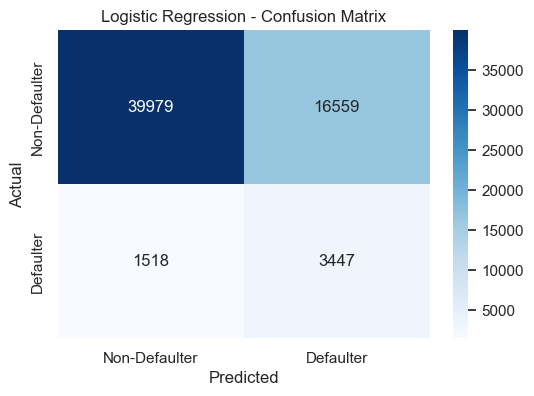

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Defaulter', 'Defaulter'],
    yticklabels=['Non-Defaulter', 'Defaulter']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

###  Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance.

It can capture nonlinear relationships and interactions between financial and customer-related features. Class weighting is applied to address the imbalance in the target variable.

In [103]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=50,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [104]:
y_pred_rf = random_forest_model.predict(X_test_processed)

y_prob_rf = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest Evaluation")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Evaluation
--------------------------------
Accuracy: 0.7685
Precision: 0.193
Recall: 0.5871
F1 Score: 0.2905
ROC-AUC: 0.7588
PR-AUC: 0.2391

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.78      0.86     56538
           1       0.19      0.59      0.29      4965

    accuracy                           0.77     61503
   macro avg       0.57      0.69      0.58     61503
weighted avg       0.89      0.77      0.82     61503



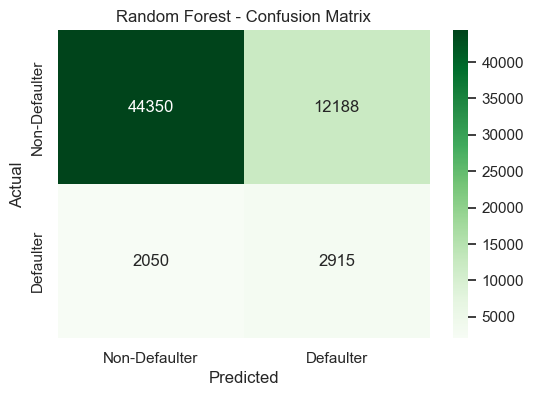

In [105]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Non-Defaulter', 'Defaulter'],
    yticklabels=['Non-Defaulter', 'Defaulter']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### HistGradientBoosting Classifier

HistGradientBoosting is an ensemble learning algorithm that builds decision trees sequentially to improve predictive performance.

It uses histogram-based feature binning to make training efficient. The model is evaluated using the same classification metrics as the previous algorithms to ensure a fair comparison.

In [107]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Convert only if the data is sparse
from scipy import sparse

if sparse.issparse(X_train_processed):
    X_train_dense = X_train_processed.toarray()
else:
    X_train_dense = X_train_processed

if sparse.issparse(X_test_processed):
    X_test_dense = X_test_processed.toarray()
else:
    X_test_dense = X_test_processed

print("Dense training shape:", X_train_dense.shape)
print("Dense testing shape:", X_test_dense.shape)

Dense training shape: (246008, 323)
Dense testing shape: (61503, 323)


In [108]:
hist_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

hist_model.fit(X_train_dense, y_train)

print("HistGradientBoosting training completed.")

HistGradientBoosting training completed.


In [109]:
y_pred_hgb = hist_model.predict(X_test_dense)

y_prob_hgb = hist_model.predict_proba(X_test_dense)[:, 1]

print("HistGradientBoosting Evaluation")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_hgb), 4))
print("Precision:", round(precision_score(y_test, y_pred_hgb), 4))
print("Recall:", round(recall_score(y_test, y_pred_hgb), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_hgb), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_hgb), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_hgb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_hgb))

HistGradientBoosting Evaluation
--------------------------------
Accuracy: 0.9201
Precision: 0.571
Recall: 0.0397
F1 Score: 0.0742
ROC-AUC: 0.7793
PR-AUC: 0.2777

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.57      0.04      0.07      4965

    accuracy                           0.92     61503
   macro avg       0.75      0.52      0.52     61503
weighted avg       0.89      0.92      0.89     61503



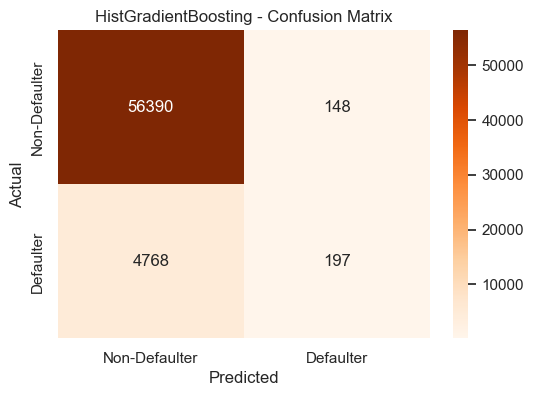

In [110]:
cm_hgb = confusion_matrix(y_test, y_pred_hgb)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_hgb,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Non-Defaulter', 'Defaulter'],
    yticklabels=['Non-Defaulter', 'Defaulter']
)

plt.title('HistGradientBoosting - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Model Comparison Report

Three classification algorithms were evaluated using the same training and testing datasets.

The comparison considers Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC. Special attention is given to recall and PR-AUC because the dataset contains a highly imbalanced target variable.

In [111]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'HistGradientBoosting'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_hgb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_hgb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_hgb)
    ],
    'F1_Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_hgb)
    ],
    'ROC_AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_hgb)
    ],
    'PR_AUC': [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_hgb)
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression,0.7061,0.1723,0.6943,0.2761,0.7698,0.2563
1,Random Forest,0.7685,0.1930,0.5871,0.2905,0.7588,0.2391
2,HistGradientBoosting,0.9201,0.5710,0.0397,0.0742,0.7793,0.2777


### Classification Threshold Optimization

The default classification threshold of 0.5 may not provide the desired balance between precision and recall for an imbalanced dataset.

A separate validation subset is created from the training data. The classification threshold is selected using validation predictions, and the selected threshold is subsequently evaluated on the independent testing dataset.

In [112]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Fit preprocessing only on the smaller training subset
validation_preprocessor = clone(preprocessor)

X_subtrain_processed = validation_preprocessor.fit_transform(X_subtrain)
X_validation_processed = validation_preprocessor.transform(X_validation)

print("Sub-training shape:", X_subtrain_processed.shape)
print("Validation shape:", X_validation_processed.shape)

Sub-training shape: (196806, 323)
Validation shape: (49202, 323)


In [113]:
validation_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

validation_model.fit(X_subtrain_processed, y_subtrain)

validation_probabilities = validation_model.predict_proba(
    X_validation_processed
)[:, 1]

print("Validation model training completed.")

Validation model training completed.


###  Evaluating Different Classification Thresholds

Different classification thresholds are evaluated using validation probabilities.

Precision, Recall and F1-score are calculated at each threshold. The threshold producing the highest validation F1-score is selected as the initial operating threshold.

In [114]:
from sklearn.metrics import precision_recall_curve

thresholds_to_test = np.arange(0.05, 0.51, 0.05)

threshold_results = []

for threshold in thresholds_to_test:

    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_validation, validation_predictions,
            zero_division=0
        ),
        'Recall': recall_score(
            y_validation, validation_predictions
        ),
        'F1_Score': f1_score(
            y_validation, validation_predictions,
            zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

,Threshold,Precision,Recall,F1_Score
0,0.05,0.1380,0.8406,0.2371
1,0.10,0.1971,0.6032,0.2972
2,0.15,0.2505,0.4439,0.3203
3,0.20,0.2880,0.3157,0.3012
4,0.25,0.3338,0.2324,0.2740
5,0.30,0.3729,0.1677,0.2313
6,0.35,0.4250,0.1249,0.1930
7,0.40,0.4643,0.0851,0.1438
8,0.45,0.4842,0.0541,0.0974
9,0.50,0.5114,0.0340,0.0637


In [115]:
best_threshold_row = threshold_results_df.loc[
    threshold_results_df['F1_Score'].idxmax()
]

best_threshold = best_threshold_row['Threshold']

print("Selected threshold:", best_threshold)
print("Validation Precision:", round(best_threshold_row['Precision'], 4))
print("Validation Recall:", round(best_threshold_row['Recall'], 4))
print("Validation F1-score:", round(best_threshold_row['F1_Score'], 4))

Selected threshold: 0.15000000000000002
Validation Precision: 0.2505
Validation Recall: 0.4439
Validation F1-score: 0.3203


### Independent Test Evaluation After Threshold Optimization

The threshold selected using validation data is applied to the independent testing dataset.

The validation preprocessing pipeline and trained validation model are used consistently. This ensures that the testing dataset remains independent and is not used for threshold selection.

In [116]:
# Transform test data using the validation-fitted preprocessor
X_test_validation_processed = validation_preprocessor.transform(X_test)

# Predict default probabilities
y_prob_hgb_tuned = validation_model.predict_proba(
    X_test_validation_processed
)[:, 1]

# Apply the selected threshold
y_pred_hgb_tuned = (
    y_prob_hgb_tuned >= best_threshold
).astype(int)

print("Selected threshold:", round(best_threshold, 2))
print("Test predictions generated successfully.")

Selected threshold: 0.15
Test predictions generated successfully.


In [117]:
print("HistGradientBoosting - Tuned Threshold Evaluation")
print("--------------------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_hgb_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_hgb_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_hgb_tuned), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_hgb_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_hgb_tuned), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_hgb_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_hgb_tuned))

HistGradientBoosting - Tuned Threshold Evaluation
--------------------------------------------------
Accuracy: 0.8523
Precision: 0.2616
Recall: 0.4552
F1 Score: 0.3322
ROC-AUC: 0.7772
PR-AUC: 0.2695

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.26      0.46      0.33      4965

    accuracy                           0.85     61503
   macro avg       0.61      0.67      0.62     61503
weighted avg       0.89      0.85      0.87     61503



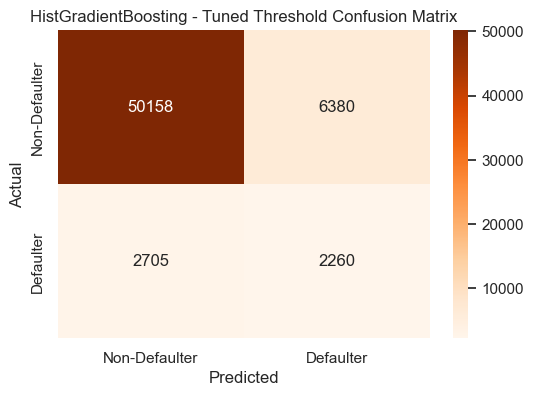

In [118]:
cm_hgb_tuned = confusion_matrix(y_test, y_pred_hgb_tuned)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_hgb_tuned,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Non-Defaulter', 'Defaulter'],
    yticklabels=['Non-Defaulter', 'Defaulter']
)

plt.title('HistGradientBoosting - Tuned Threshold Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

###  Final Model Comparison

The performance of Logistic Regression, Random Forest, default HistGradientBoosting, and threshold-optimized HistGradientBoosting is compared.

The comparison includes Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC. The impact of threshold optimization is also considered when identifying the most suitable model configuration.

In [119]:
final_model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'HistGradientBoosting (0.50)',
        'HistGradientBoosting (0.15)'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_hgb),
        accuracy_score(y_test, y_pred_hgb_tuned)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_hgb),
        precision_score(y_test, y_pred_hgb_tuned)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_hgb),
        recall_score(y_test, y_pred_hgb_tuned)
    ],
    'F1_Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_hgb),
        f1_score(y_test, y_pred_hgb_tuned)
    ],
    'ROC_AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_hgb),
        roc_auc_score(y_test, y_prob_hgb_tuned)
    ],
    'PR_AUC': [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_hgb),
        average_precision_score(y_test, y_prob_hgb_tuned)
    ]
})

display(final_model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression,0.7061,0.1723,0.6943,0.2761,0.7698,0.2563
1,Random Forest,0.7685,0.1930,0.5871,0.2905,0.7588,0.2391
2,HistGradientBoosting (0.50),0.9201,0.5710,0.0397,0.0742,0.7793,0.2777
3,HistGradientBoosting (0.15),0.8523,0.2616,0.4552,0.3322,0.7772,0.2695


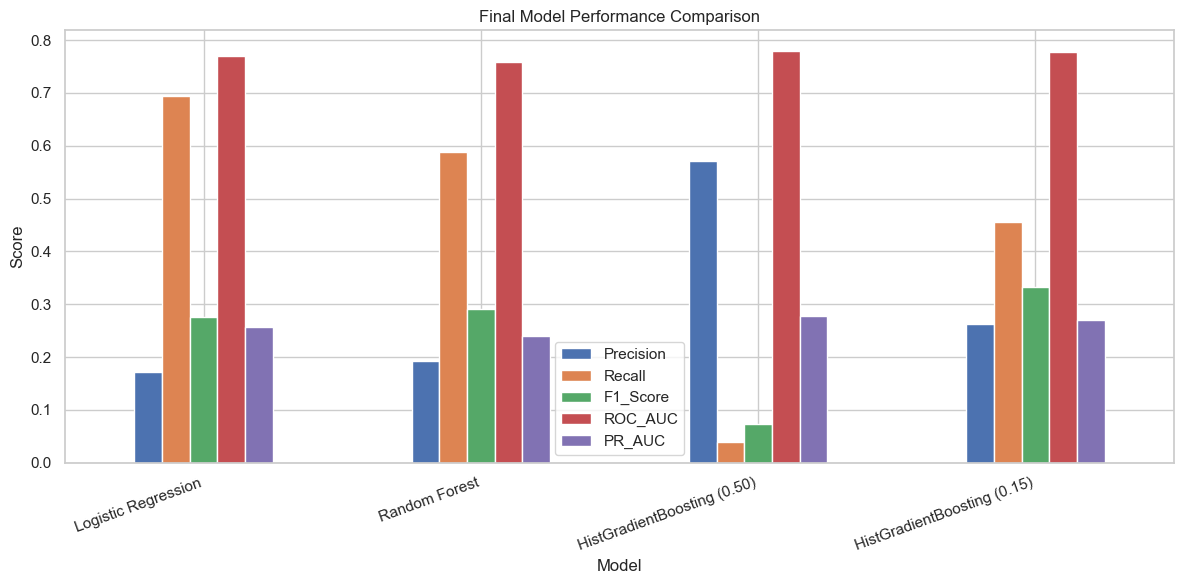

In [120]:
metrics_to_plot = [
    'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC'
]

final_model_comparison.set_index('Model')[metrics_to_plot].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Final Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=20, ha='right')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

### Feature Importance Analysis

Permutation Importance is used to identify the features that contribute most to the predictive performance of the HistGradientBoosting model.

The method measures the reduction in model performance when individual features are randomly shuffled. A larger reduction indicates greater predictive importance.

The analysis uses validation data and PR-AUC as the evaluation metric because the target variable is imbalanced.

In [121]:
from sklearn.inspection import permutation_importance

# Use a manageable validation sample
X_importance = X_validation_processed[:5000]
y_importance = y_validation.iloc[:5000]

perm_result = permutation_importance(
    validation_model,
    X_importance,
    y_importance,
    scoring='average_precision',
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

print("Permutation importance calculation completed.")

Permutation importance calculation completed.


In [122]:
feature_names = validation_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': perm_result.importances_mean
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 20 Important Features:")
display(importance_df.head(20).round(5))

Top 20 Important Features:


,Feature,Importance
29,num__EXT_SOURCE_3,0.03915
28,num__EXT_SOURCE_2,0.03884
4,num__AMT_GOODS_PRICE,0.01318
27,num__EXT_SOURCE_1,0.01101
185,cat__CODE_GENDER_F,0.00703
175,num__LATE_PAYMENT_RATE,0.00651
3,num__AMT_ANNUITY,0.00488
213,cat__NAME_FAMILY_STATUS_Married,0.00466
2,num__AMT_CREDIT,0.00401
6,num__DAYS_BIRTH,0.00362


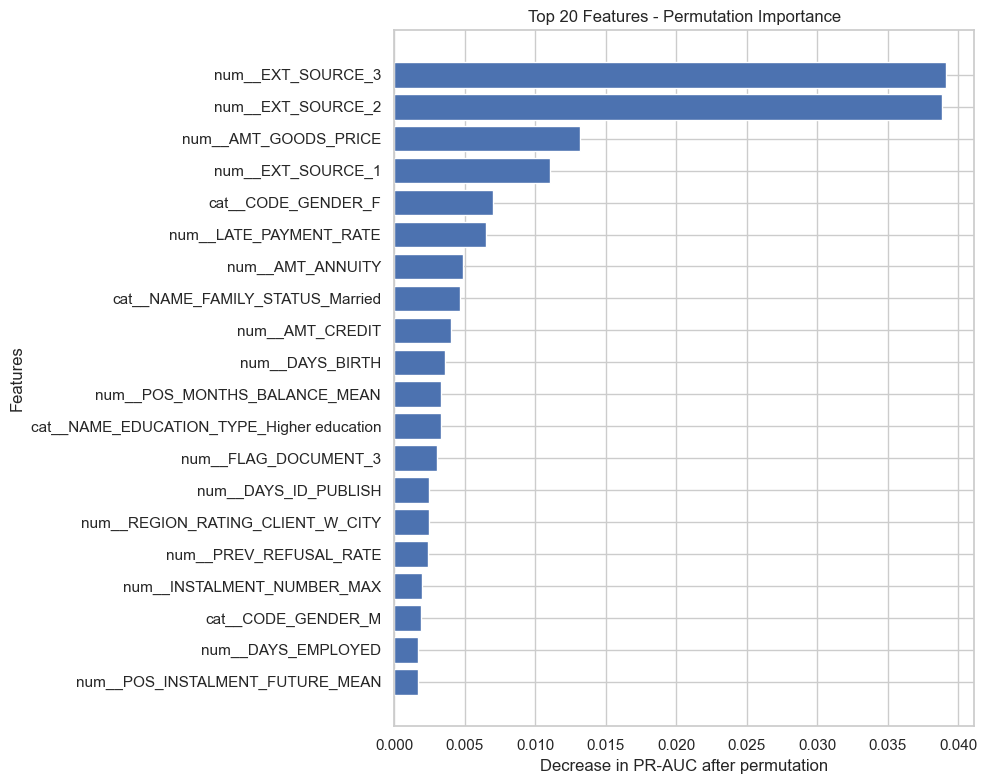

In [123]:
top_features = importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 20 Features - Permutation Importance')
plt.xlabel('Decrease in PR-AUC after permutation')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

###  Challenges Faced and Solutions

During the development of the Home Loan Default Prediction system, several data-related and modelling challenges were encountered.

| Challenge | Solution |
|---|---|
| Large datasets | Aggregated supporting datasets at customer level before merging. |
| Missing values | Applied median imputation for numerical features and most-frequent imputation for categorical features. |
| Class imbalance | Used stratified splitting, class weighting and multiple evaluation metrics. |
| DAYS_EMPLOYED anomaly | Created an anomaly indicator and replaced the placeholder value with NaN. |
| Multiple supporting datasets | Used customer-level aggregation and left joins to preserve all main applicants. |
| Categorical variables | Applied One-Hot Encoding. |
| Data leakage risk | Fitted preprocessing transformations using training data only. |
| High-dimensional features | Used a ColumnTransformer preprocessing pipeline. |
| Incorrect default classification threshold | Evaluated different thresholds using a separate validation dataset. |
| Sparse matrix conversion issue | Checked the data type before attempting sparse-to-dense conversion. |
| Model interpretability | Used permutation importance to identify influential features. |

These solutions helped improve data quality, preserve customer records, and establish a consistent machine learning evaluation process.

###  Final Model Selection and Justification

Based on the experimental results, HistGradientBoosting with a classification threshold of 0.15 achieved the highest F1-score of 0.3322 among the evaluated model configurations.

The tuned model achieved:

- Accuracy: 85.23%
- Precision: 26.16%
- Recall: 45.52%
- F1-score: 33.22%
- ROC-AUC: 0.7772
- PR-AUC: 0.2695

The threshold optimization improved the model's ability to identify potential defaulters compared with the default threshold of 0.50.

Therefore, HistGradientBoosting with a threshold of 0.15 is selected as the leading experimental model based on F1-score. Further threshold calibration, fairness assessment, external validation and business-cost analysis would be required before production deployment.

###  Project Conclusion

The Home Loan Default Prediction project developed a machine learning-based approach to identify customers who may be at risk of loan default.

The project involved exploratory data analysis, data cleaning, feature engineering, integration of multiple financial datasets, missing-value treatment, categorical encoding and predictive model development.

Three machine learning algorithms were evaluated: Logistic Regression, Random Forest and HistGradientBoosting.

Among the tested configurations, HistGradientBoosting with a threshold of 0.15 achieved the highest F1-score of 33.22%. The feature importance analysis identified external credit scores, loan-related financial variables and historical repayment behaviour as important predictive features.

The project demonstrates how machine learning can support financial risk analysis by identifying potential default patterns and assisting further investigation.

However, model predictions should be treated as risk indicators rather than automatic loan approval or rejection decisions. Fairness, transparency, regulatory compliance and human oversight are essential before practical use.

In [124]:
from sklearn.ensemble import HistGradientBoostingClassifier

final_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

final_model.fit(X_train_processed, y_train)

print("Final model training completed successfully.")

Final model training completed successfully.


In [125]:
y_final_prob = final_model.predict_proba(X_test_processed)[:, 1]

FINAL_THRESHOLD = 0.15

y_final_pred = (
    y_final_prob >= FINAL_THRESHOLD
).astype(int)

print("Final predictions generated.")

Final predictions generated.


In [126]:
print("FINAL MODEL PERFORMANCE")
print("------------------------")

print("Threshold:", FINAL_THRESHOLD)
print("Accuracy:", round(accuracy_score(y_test, y_final_pred), 4))
print("Precision:", round(precision_score(y_test, y_final_pred), 4))
print("Recall:", round(recall_score(y_test, y_final_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_final_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_final_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_final_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_final_pred))

FINAL MODEL PERFORMANCE
------------------------
Threshold: 0.15
Accuracy: 0.8535
Precision: 0.266
Recall: 0.4634
F1 Score: 0.338
ROC-AUC: 0.7793
PR-AUC: 0.2777

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.27      0.46      0.34      4965

    accuracy                           0.85     61503
   macro avg       0.61      0.68      0.63     61503
weighted avg       0.89      0.85      0.87     61503



Final Confusion Matrix:
[[50190  6348]
 [ 2664  2301]]


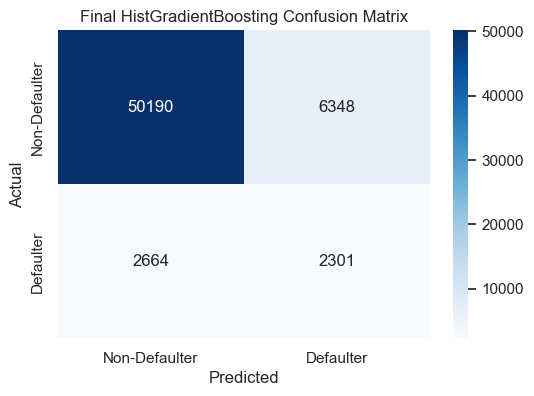

In [127]:
final_cm = confusion_matrix(y_test, y_final_pred)

print("Final Confusion Matrix:")
print(final_cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    final_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Defaulter', 'Defaulter'],
    yticklabels=['Non-Defaulter', 'Defaulter']
)

plt.title('Final HistGradientBoosting Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Saving the Final Model

The trained HistGradientBoosting model and fitted preprocessing pipeline are saved using Joblib. The selected classification threshold is also stored for consistent future predictions.

In [128]:
import joblib

model_artifact = {
    'model': final_model,
    'preprocessor': preprocessor,
    'threshold': FINAL_THRESHOLD,
    'model_name': 'HistGradientBoosting',
    'feature_columns': X_train.columns.tolist()
}

joblib.dump(
    model_artifact,
    'home_loan_default_model.pkl'
)

print("Model and preprocessing pipeline saved successfully.")

Model and preprocessing pipeline saved successfully.


### Loading the Saved Model

The saved model artifact is loaded using Joblib. It contains the trained model, preprocessing pipeline, selected threshold and feature columns.

In [129]:
import joblib

loaded_artifact = joblib.load('home_loan_default_model.pkl')

loaded_model = loaded_artifact['model']
loaded_preprocessor = loaded_artifact['preprocessor']
loaded_threshold = loaded_artifact['threshold']
loaded_features = loaded_artifact['feature_columns']

print("Saved model loaded successfully.")
print("Model:", loaded_artifact['model_name'])
print("Threshold:", loaded_threshold)

Saved model loaded successfully.
Model: HistGradientBoosting
Threshold: 0.15


In [130]:
def predict_home_loan_default(customer_data):

    # Ensure all required features are present and ordered
    customer_data = customer_data[loaded_features]

    # Apply saved preprocessing
    processed_data = loaded_preprocessor.transform(customer_data)

    # Predict default probability
    probabilities = loaded_model.predict_proba(
        processed_data
    )[:, 1]

    # Apply selected threshold
    predictions = (probabilities >= loaded_threshold).astype(int)

    results = pd.DataFrame({
        'Default_Probability': probabilities,
        'Predicted_Class': predictions,
        'Risk_Category': [
            'Potential Default Risk' if value == 1
            else 'Lower Predicted Default Risk'
            for value in predictions
        ]
    }, index=customer_data.index)

    return results


print("Prediction function created successfully.")

Prediction function created successfully.


In [131]:
sample_customer = X_test.iloc[[0]].copy()

sample_prediction = predict_home_loan_default(
    sample_customer
)

display(sample_prediction)

,Default_Probability,Predicted_Class,Risk_Category
256571,0.041036,0,Lower Predicted Default Risk


# Final Project Summary

## Project: Home Loan Default Prediction

### Objective
The objective of this project is to develop a machine learning system that identifies customers who may be at risk of defaulting on home loans.

### Datasets Used
The project uses seven datasets:
1. application_train.csv
2. bureau.csv
3. bureau_balance.csv
4. previous_application.csv
5. POS_CASH_balance.csv
6. credit_card_balance.csv
7. installments_payments.csv

### Data Analysis and Feature Engineering
- Performed exploratory data analysis.
- Identified missing values, anomalies and outliers.
- Analyzed the target variable and class imbalance.
- Created customer-level features from historical credit datasets.
- Integrated supporting datasets using customer IDs.
- Applied missing-value imputation, categorical encoding and feature scaling.

### Machine Learning Algorithms
The following algorithms were evaluated:
1. Logistic Regression
2. Random Forest
3. HistGradientBoosting

### Final Model
HistGradientBoosting was selected as the leading experimental model using a classification threshold of 0.15.

### Final Test Performance
- Accuracy: 85.35%
- Precision: 26.60%
- Recall: 46.34%
- F1-score: 33.80%
- ROC-AUC: 0.7793
- PR-AUC: 0.2777

### Feature Importance
Permutation importance identified EXT_SOURCE_3, EXT_SOURCE_2, AMT_GOODS_PRICE, EXT_SOURCE_1 and LATE_PAYMENT_RATE among the most influential predictive features.

### Conclusion
The project demonstrates how machine learning can analyze customer financial information and historical repayment behaviour to identify potential home loan default risk.

The developed model can support financial risk analysis and further investigation. Its predictions should not be used as automatic loan approval or rejection decisions without further validation, fairness assessment and appropriate human oversight.